# Drone-Based Delivery Optimization
### Multi-Depot Vehicle Routing with Energy Constraints — a Team-Orienteering Formulation

**Combinatorial Optimization & Metaheuristics — Project 3**  
*Third Year · National School of Artificial Intelligence (ENSIA) · 2026*

**Team:** _BRIHMOUCHE Aicha_ · _LALAM Sofia_

---

## Problem context

A logistics company operates a small fleet of identical drones delivering packages from a depot to a
set of customers. Because drone resources (battery, payload, fleet size) are scarce — the realistic
situation for an emerging Algerian drone-delivery market — we model the problem as a
**Team Orienteering Problem (TOP)** built on top of **VRP / CVRP / EVRP**: a pre-processing step
selects the highest-priority customers, and the optimizer then designs energy-feasible routes that
serve that selected set.

**Objective:** maximise collected profit/urgency while minimising total energy, subject to battery,
payload, no-fly-zone, and route-connectivity constraints.

---

## What this notebook contains

| Section | Project requirement |
|---|---|
| **Formulation 1 — Arc-Based MILP** | Classical optimization model (arcs, MTZ, big-M) |
| **Formulation 2 — Set-Partitioning** | Alternative *route-based* abstraction (proven equal optimum to F1) |
| **Complexity study** | NP-hardness via reduction from TSP |
| **Exact method — custom Branch & Bound** | LP-relaxation B&B (validated against CBC and F2) |
| **Metaheuristics — GA & SA** | One population-based + one local-search method |
| **Problem-specific operators** | Clustering · route merging · energy-aware neighbourhood · no-fly handling |
| **Experimental study (≥ 10 instances)** | Feasibility-gated comparison of all methods + plots |
| **Comparative analysis** | F1 vs F2, exact vs heuristic, operators on/off |


Mathematical Formulation
Sets:

- $  N  $: Set of selected high-priority customers (after pre-processing)
- $  N_0 = N \cup \{0\}  $: Set of all nodes, where 0 is the depot
- $  K = \{1, 2, \dots, m\}  $: Set of homogeneous drones

Parameters:

- $  d_{ij}  $: Euclidean distance between nodes $  i  $ and $  j  $
- $  e_{ij}  $: Energy consumption for traveling from $  i  $ to $  j  $
- $  q_i  $: Demand (payload) of customer $  i \in N  $
- $  p_i  $: Profit/urgency score of customer $  i  $ (used in pre-processing)
- $  B  $: Initial battery capacity of each drone (one charge per drone per day)
- $  Q  $: Maximum payload capacity of each drone
- $  M  $: Sufficiently large constant (Big-M)
- $  \lambda  $: Small positive weight for the secondary objective (energy minimization)

Decision Variables:

- $  x_{ijk} \in \{0,1\}  $: Binary variable equal to 1 if drone $  k  $ travels directly from node $  i  $ to node $  j  $
- $  u_{ik} \geq 0  $: Cumulative payload carried by drone $  k  $ upon arrival at node $  i  $
- $  b_{ik} \geq 0  $: Remaining battery of drone $  k  $ upon arrival at node $  i  $

Objective Function:
$$\max \quad \sum_{i \in N} p_i \ - \ \lambda \sum_{k \in K} \sum_{i \in N_0} \sum_{j \in N_0} e_{ij} \, x_{ijk}$$

Constraints
1. Each Customer in $  N  $ Served Exactly Once (after the TOP pre-processing)
$$\sum_{k \in K} \sum_{j \in N_0} x_{ijk} = 1 \quad \forall i \in N$$
2. Flow Conservation
$$\sum_{i \in N_0} x_{ijk} = \sum_{j \in N_0} x_{jik} \quad \forall j \in N_0, \ \forall k \in K$$

3. Battery Constraints (One single charge per drone per day – No recharging)

Initial battery at the beginning:$$b_{0k} = B \quad \forall k \in K$$
Battery consumption on each arc:$$b_{ik} - e_{ij} \cdot x_{ijk} \geq b_{jk} - M(1 - x_{ijk}) \quad \forall i,j \in N_0, \ \forall k \in K$$
Battery limits:$$0 \leq b_{ik} \leq B \quad \forall i \in N_0, \ \forall k \in K$$

4. Payload Constraints (Delivery with unloading at customers + reloading at depot)

Payload update (delivery style):$$u_{ik} - q_j \geq u_{jk} - M(1 - x_{ijk}) \quad \forall i \in N_0, \ j \in N, \ \forall k \in K$$
Payload capacity limit:$$0 \leq u_{ik} \leq Q \quad \forall i \in N_0, \ \forall k \in K$$
Payload reset when returning to depot (reload):$$u_{0k} = 0 \quad \forall k \in K$$

5. Variable Domains

- $  x_{ijk} \in \{0,1\}  $
- $  u_{ik} \geq 0  $, $  b_{ik} \geq 0  $

In [1]:
import numpy as np
import pandas as pd
from pulp import *
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Optional
import time
import copy
from collections import deque
import warnings
warnings.filterwarnings('ignore')
 
# Set random seed for reproducibility
np.random.seed(42)
 
# Plotting configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [2]:
class ProblemConfig:
    """Configuration class for drone delivery problem parameters"""
    
    def __init__(self):
        # Fleet parameters
        self.num_drones = 2  # Number of available drones (m)
        self.battery_capacity = 100.0  # Battery capacity B (energy units)
        self.payload_capacity = 10.0  # Payload capacity Q (kg)
        
        # Energy model parameters (Dorling et al. 2016 linear model)
        self.alpha = 0.5  # Energy per kg per km (Wh/kg/km)
        self.beta = 2.0   # Base energy per km (Wh/km)
        self.drone_mass = 3.0  # Base drone mass (kg)
        self.battery_mass = 1.0  # Battery mass (kg)
        
        # TOP parameters
        self.lambda_weight = 0.05  # Weight for energy penalty in objective
        
        # Multi-trip parameters
        self.max_trips_per_drone = 3  # Maximum trips per drone
        
        # Branch & Bound parameters
        self.bnb_time_limit = 300  # seconds (5 minutes)
        self.bnb_gap_tolerance = 0.05  # 5% optimality gap

        # Circles in the same coordinate system as customer locations (km).
        # IMPORTANT: For the default 50x50 area the depot is at (25, 25). Do not place a
        # zone centered on the depot with large radius: the naive arc test treats any
        # endpoint inside the disk as a blocked arc, which forbids ALL depot ↔ customer
        # legs and makes the MILP infeasible once those arcs are fixed to x == 0.
        self.no_fly_zones = [
            (38.0, 38.0, 7.0),
            (12.0, 12.0, 5.5),
            (40.0, 12.0, 6.0),
        ]
        
    def energy_consumption(self, distance: float, payload_mass: float) -> float:
        """
        Calculate energy consumption using linear model
        E_ij = (α * m_total + β) * d_ij
        
        Args:
            distance: Distance traveled (km)
            payload_mass: Current payload mass (kg)
            
        Returns:
            Energy consumed (Wh)
        """
        total_mass = self.drone_mass + self.battery_mass + payload_mass
        return (self.alpha * total_mass + self.beta) * distance
    
    def __repr__(self):
        return f"ProblemConfig(drones={self.num_drones}, B={self.battery_capacity}, Q={self.payload_capacity})"

In [3]:
config = ProblemConfig()
print(f"✓ Problem configuration created: {config}")

✓ Problem configuration created: ProblemConfig(drones=2, B=100.0, Q=10.0)


In [4]:
class InstanceGenerator:
    """Generate drone delivery problem instances"""
    
    def __init__(self, config: ProblemConfig):
        self.config = config
        
    def generate_instance(self, 
                         num_customers: int,
                         area_size: Tuple[float, float] = (50, 50),
                         urgency_distribution: str = 'mixed') -> Dict:
        """
        Generate a problem instance
        
        Args:
            num_customers: Number of customers to generate
            area_size: (width, height) of service area in km
            urgency_distribution: 'uniform', 'high_priority', or 'mixed'
            
        Returns:
            Dictionary containing instance data
        """
        # Generate depot at center
        depot_x = area_size[0] / 2
        depot_y = area_size[1] / 2
        
        # Generate customer locations (avoid depot vicinity) AND ensure battery-feasible round trip
        # Required when enforcing 'all selected customers must be served' under battery B.
        customers_x = []
        customers_y = []

        # Conservative payload used for reachability screening (helps avoid generating impossible instances)
        payload_screen = 0.6 * self.config.payload_capacity

        for _ in range(num_customers):
            attempts = 0
            while True:
                attempts += 1
                if attempts > 5000:
                    raise RuntimeError(
                        "Could not generate battery-feasible customers. Increase B, reduce area_size, or relax screening."
                    )

                x = np.random.uniform(0, area_size[0])
                y = np.random.uniform(0, area_size[1])

                # Ensure minimum distance from depot (2 km)
                dist_to_depot = np.sqrt((x - depot_x) ** 2 + (y - depot_y) ** 2)
                if dist_to_depot <= 2.0:
                    continue

                # Battery-feasible necessary condition: depot -> customer -> depot within one charge
                e_out = self.config.energy_consumption(dist_to_depot, payload_screen)
                e_back = self.config.energy_consumption(dist_to_depot, payload_screen)
                if e_out + e_back > self.config.battery_capacity:
                    continue

                customers_x.append(x)
                customers_y.append(y)
                break
        
        # Generate demands (package weights) - realistic distribution
        # Most packages are 1-5 kg, some heavier ones
        demands = np.random.gamma(shape=2.0, scale=1.5, size=num_customers)
        demands = np.clip(demands, 0.5, 8.0)  # Between 0.5 and 8 kg
        
        # Generate urgency/profit scores based on distribution
        if urgency_distribution == 'uniform':
            urgencies = np.random.uniform(1, 10, num_customers)
        elif urgency_distribution == 'high_priority':
            # More high-urgency customers (medicine, urgent packages)
            urgencies = np.random.choice([8, 9, 10], size=num_customers, p=[0.3, 0.4, 0.3])
            # Add some medium priority
            mask = np.random.rand(num_customers) < 0.3
            urgencies[mask] = np.random.uniform(4, 7, mask.sum())
        else:  # mixed
            # Realistic distribution: few very urgent, many medium, some low
            urgencies = np.random.choice(
                [10, 9, 8, 6, 5, 3],
                size=num_customers,
                p=[0.1, 0.15, 0.2, 0.3, 0.15, 0.1]
            )
        
        # Calculate distance matrix (Euclidean)
        n = num_customers
        all_x = [depot_x] + customers_x
        all_y = [depot_y] + customers_y

        distance_matrix = np.zeros((n + 1, n + 1))
        energy_matrix = np.zeros((n + 1, n + 1))
        feasible_arc = np.ones((n + 1, n + 1), dtype=bool)   # True = allowed

        avg_payload = np.mean(demands)


        for i in range(n + 1):
            for j in range(n + 1):
                if i == j:
                    continue

                dist = np.sqrt((all_x[i] - all_x[j])**2 + (all_y[i] - all_y[j])**2)
                distance_matrix[i, j] = dist
                    

                # Check if this arc intersects any no-fly zone
                if self.intersects_no_fly_zone(all_x[i], all_y[i], all_x[j], all_y[j]):
                    feasible_arc[i, j] = False
                    energy_matrix[i, j] = 0
                else:
                    energy_matrix[i, j] = self.config.energy_consumption(
                        dist, avg_payload * 0.6
                    )
        
    
        
        instance = {
            'num_customers': num_customers,
            'depot': (depot_x, depot_y),
            'customers': list(zip(customers_x, customers_y)),
            'demands': demands.tolist(),
            'urgencies': urgencies.tolist(),
            'distance_matrix': distance_matrix,
            'energy_matrix': energy_matrix,
            'feasible_arc': feasible_arc,
            'area_size': area_size
        }
        
        return instance

    def intersects_no_fly_zone(self, x1: float, y1: float, x2: float, y2: float) -> bool:
        """True if the closed segment (x1,y1)-(x2,y2) meets any circular no-fly disk."""

        def segment_hits_disk(ax, ay, bx, by, cx, cy, r) -> bool:
            r2 = r * r
            if (ax - cx) ** 2 + (ay - cy) ** 2 <= r2:
                return True
            if (bx - cx) ** 2 + (by - cy) ** 2 <= r2:
                return True
            dx, dy = bx - ax, by - ay
            if dx == 0 and dy == 0:
                return False
            t = ((cx - ax) * dx + (cy - ay) * dy) / (dx * dx + dy * dy)
            t = max(0.0, min(1.0, t))
            px, py = ax + t * dx, ay + t * dy
            return (px - cx) ** 2 + (py - cy) ** 2 <= r2

        for cx, cy, radius in self.config.no_fly_zones:
            if segment_hits_disk(x1, y1, x2, y2, cx, cy, radius):
                return True
        return False

    
    def visualize_instance(self, instance: Dict, title: str = "Instance Visualization"):
        """Visualize the generated instance"""
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
        
        # Plot 1: Locations with urgency
        depot = instance['depot']
        customers = instance['customers']
        urgencies = instance['urgencies']
        demands = instance['demands']
        
        # Plot depot
        ax1.scatter([depot[0]], [depot[1]], c='red', s=300, marker='s', 
                   label='Depot', edgecolors='black', linewidths=2, zorder=5)
        
        # Plot customers with urgency coloring
        scatter = ax1.scatter(
            [c[0] for c in customers],
            [c[1] for c in customers],
            c=urgencies,
            s=[d * 30 for d in demands],  # Size proportional to demand
            cmap='YlOrRd',
            alpha=0.7,
            edgecolors='black',
            linewidths=1,
            zorder=3
        )
        
        # Add customer labels
        for i, (x, y) in enumerate(customers):
            ax1.annotate(f'{i+1}', (x, y), fontsize=8, ha='center', va='center')
        
        ax1.set_xlabel('X coordinate (km)')
        ax1.set_ylabel('Y coordinate (km)')
        ax1.set_title(f'{title}\n(Size ∝ Demand, Color ∝ Urgency)')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        cbar = plt.colorbar(scatter, ax=ax1)
        cbar.set_label('Urgency Score')
        
        # Plot 2: Customer characteristics
        customer_ids = list(range(1, instance['num_customers'] + 1))
        
        ax2_twin = ax2.twinx()
        
        bar1 = ax2.bar(customer_ids, urgencies, alpha=0.6, color='orange', label='Urgency')
        bar2 = ax2_twin.bar([x + 0.3 for x in customer_ids], demands, 
                           width=0.3, alpha=0.6, color='blue', label='Demand (kg)')
        
        ax2.set_xlabel('Customer ID')
        ax2.set_ylabel('Urgency Score', color='orange')
        ax2_twin.set_ylabel('Demand (kg)', color='blue')
        ax2.set_title('Customer Urgency and Demand')
        ax2.tick_params(axis='y', labelcolor='orange')
        ax2_twin.tick_params(axis='y', labelcolor='blue')
        ax2.grid(True, alpha=0.3)
        
        # Combine legends
        lines1, labels1 = ax2.get_legend_handles_labels()
        lines2, labels2 = ax2_twin.get_legend_handles_labels()
        ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
        
        plt.tight_layout()
        plt.show()
        
        # Print instance statistics
        print(f"\n{'='*60}")
        print(f"INSTANCE STATISTICS")
        print(f"{'='*60}")
        print(f"Number of customers: {instance['num_customers']}")
        print(f"Total demand: {sum(instance['demands']):.2f} kg")
        print(f"Average demand: {np.mean(instance['demands']):.2f} kg")
        print(f"Urgency range: [{min(urgencies)}, {max(urgencies)}]")
        print(f"Average urgency: {np.mean(urgencies):.2f}")
        print(f"Max distance from depot: {np.max(instance['distance_matrix'][0, 1:]):.2f} km")
        print(f"Min distance from depot: {np.min(instance['distance_matrix'][0, 1:]):.2f} km")
        print(f"{'='*60}\n")
 

In [5]:
generator = InstanceGenerator(config)
print("✓ Instance generator created")

✓ Instance generator created


Generating SMALL instance (5 customers)...


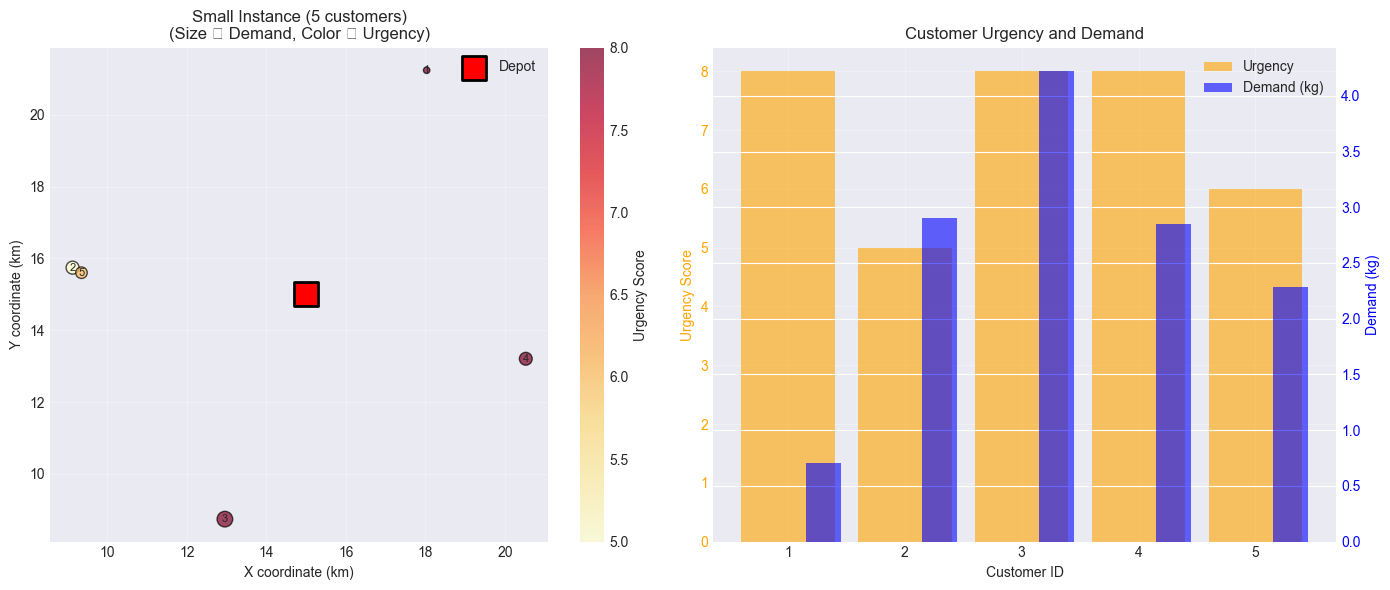


INSTANCE STATISTICS
Number of customers: 5
Total demand: 12.96 kg
Average demand: 2.59 kg
Urgency range: [5, 8]
Average urgency: 7.00
Max distance from depot: 6.94 km
Min distance from depot: 5.68 km


Generating MEDIUM instance (10 customers)...


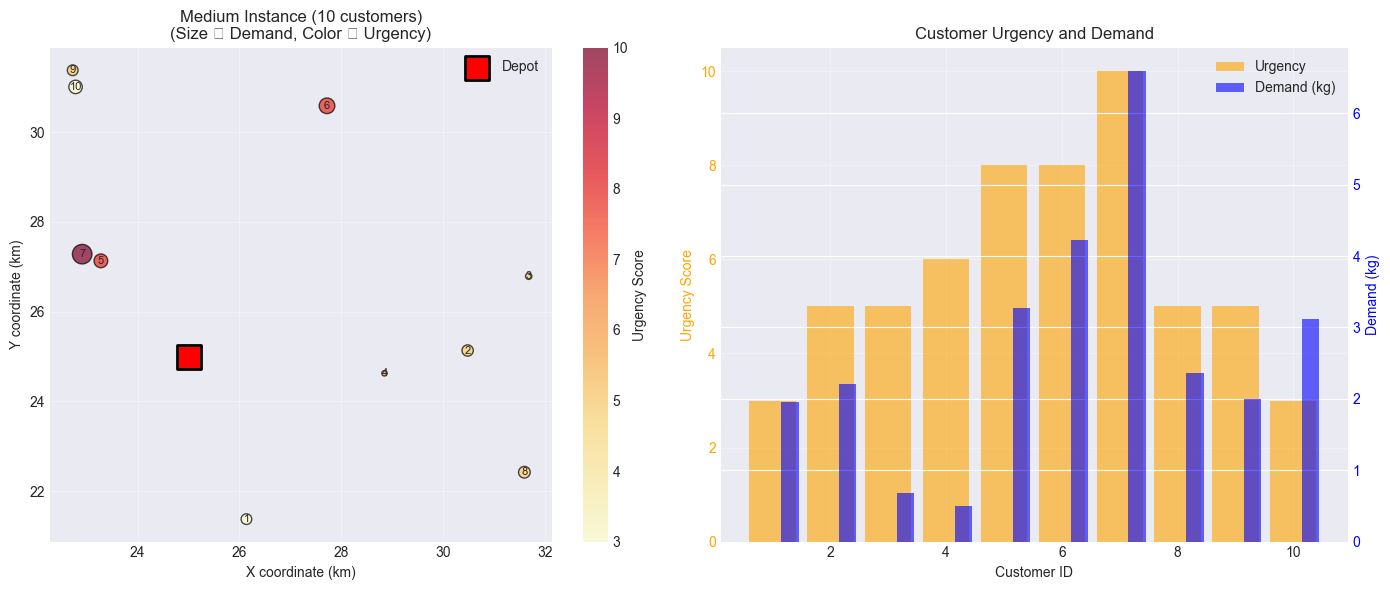


INSTANCE STATISTICS
Number of customers: 10
Total demand: 26.91 kg
Average demand: 2.69 kg
Urgency range: [3, 10]
Average urgency: 5.80
Max distance from depot: 7.08 km
Min distance from depot: 2.74 km


✓ Sample instances generated and stored


In [6]:
# Small instance for testing (5 customers)
print("Generating SMALL instance (5 customers)...")
small_instance = generator.generate_instance(
    num_customers=5,
    area_size=(30, 30),
    urgency_distribution='mixed'
)
generator.visualize_instance(small_instance, "Small Instance (5 customers)")
 
# Medium instance (10 customers)
print("\nGenerating MEDIUM instance (10 customers)...")
medium_instance = generator.generate_instance(
    num_customers=10,
    area_size=(50, 50),
    urgency_distribution='mixed'
)
generator.visualize_instance(medium_instance, "Medium Instance (10 customers)")
 
# Store instances for later use
instances = {
    'small': small_instance,
    'medium': medium_instance
}
 
print("\n✓ Sample instances generated and stored")

In [7]:
"""
Pre-processing step to select high-priority customers
Based on the TOP approach
"""
 
def preprocess_customer_selection(instance: Dict, 
                                  config: ProblemConfig,
                                  k_max: Optional[int] = None) -> Dict:
    """Select top-K customers by urgency **that are feasible to serve**.

    When the model enforces "serve all selected customers exactly once", this preprocessing
    must remove customers that are individually infeasible (e.g., cannot do depot→i→depot within B).
    """
    n = instance['num_customers']
    urgencies = np.array(instance['urgencies'])
    demands = np.array(instance['demands'])
    e = instance['energy_matrix']
    B = config.battery_capacity
    Q = config.payload_capacity

    # Feasibility filter: each selected customer must at least be reachable in a single out-and-back trip
    # (necessary condition for any serve-all model with depot start/end).
    feasible_mask = np.array([(e[0, i+1] + e[i+1, 0] <= B) and (demands[i] <= Q) for i in range(n)])
    feasible_indices = np.where(feasible_mask)[0]

    if len(feasible_indices) == 0:
        raise ValueError("No customers are individually feasible under current B/Q (round-trip + demand).")

    # If k_max not specified, estimate based on resources
    if k_max is None:
        # crude upper bound based on payload and number of drones (single tour per drone)
        k_max = min(len(feasible_indices), max(1, int(config.num_drones * (Q / max(1e-9, np.mean(demands[feasible_indices]))))))

    # Sort feasible customers by urgency (descending) and pick top-k
    sorted_feasible = feasible_indices[np.argsort(-urgencies[feasible_indices])]
    selected_indices = sorted_feasible[:k_max]
    
    # Create filtered instance
    filtered_instance = copy.deepcopy(instance)
    filtered_instance['num_customers'] = len(selected_indices)
    filtered_instance['customers'] = [instance['customers'][i] for i in selected_indices]
    filtered_instance['demands'] = [instance['demands'][i] for i in selected_indices]
    filtered_instance['urgencies'] = [instance['urgencies'][i] for i in selected_indices]
    
    # Update matrices (keep depot as index 0, reindex customers)
    new_n = len(selected_indices)
    new_distance_matrix = np.zeros((new_n + 1, new_n + 1))
    new_energy_matrix = np.zeros((new_n + 1, new_n + 1))
    
    # Map old indices to new indices (depot remains 0)
    index_mapping = [0] + [i + 1 for i in selected_indices]
    
    for new_i in range(new_n + 1):
        for new_j in range(new_n + 1):
            old_i = index_mapping[new_i]
            old_j = index_mapping[new_j]
            new_distance_matrix[new_i, new_j] = instance['distance_matrix'][old_i, old_j]
            new_energy_matrix[new_i, new_j] = instance['energy_matrix'][old_i, old_j]

    old_fa = instance.get("feasible_arc")
    if old_fa is not None:
        old_fa = np.array(old_fa, dtype=bool)
        new_feasible = np.zeros((new_n + 1, new_n + 1), dtype=bool)
        for new_i in range(new_n + 1):
            for new_j in range(new_n + 1):
                if new_i == new_j:
                    continue
                oi = index_mapping[new_i]
                oj = index_mapping[new_j]
                new_feasible[new_i, new_j] = bool(old_fa[oi, oj])
        filtered_instance["feasible_arc"] = new_feasible
    
    filtered_instance['distance_matrix'] = new_distance_matrix
    filtered_instance['energy_matrix'] = new_energy_matrix
    filtered_instance['original_indices'] = selected_indices.tolist()
    filtered_instance['k_max'] = k_max
    
    print(f"\n{'='*60}")
    print(f"PREPROCESSING: Customer Selection (TOP Element)")
    print(f"{'='*60}")
    print(f"Original customers: {n}")
    print(f"Selected customers (K_max): {k_max}")
    print(f"Selection rate: {k_max/n*100:.1f}%")
    print(f"Selected customer IDs: {[i+1 for i in selected_indices]}")
    print(f"Total urgency of selected: {sum(filtered_instance['urgencies']):.1f}")
    print(f"Total urgency of all: {sum(instance['urgencies']):.1f}")
    print(f"Urgency captured: {sum(filtered_instance['urgencies'])/sum(instance['urgencies'])*100:.1f}%")
    print(f"{'='*60}\n")
    
    return filtered_instance
 
 

In [8]:
# Apply preprocessing to medium instance
preprocessed_medium = preprocess_customer_selection(medium_instance, config, k_max=7)
 
print("✓ Preprocessing complete")


PREPROCESSING: Customer Selection (TOP Element)
Original customers: 10
Selected customers (K_max): 7
Selection rate: 70.0%
Selected customer IDs: [np.int64(7), np.int64(5), np.int64(6), np.int64(4), np.int64(2), np.int64(3), np.int64(8)]
Total urgency of selected: 47.0
Total urgency of all: 58.0
Urgency captured: 81.0%

✓ Preprocessing complete


In [9]:
class DroneDeliveryMILP:
    """Arc-based MILP formulation for drone delivery problem"""
    
    def __init__(self, instance: Dict, config: ProblemConfig):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']  # Number of customers
        self.m = config.num_drones  # Number of drones
        self.model = None
        self.variables = {}
        
    def build_model(self):
        """Arc-Based MILP (serve-all selected customers) with multi-trip drones.

        We model each possible trip as its own vehicle: V = num_drones * max_trips_per_drone.
        Each trip starts/ends at the depot with a full battery, which matches the "no recharging mid-route"
        assumption while still allowing multiple depot returns per drone (across trips).
        """
        R = int(getattr(self.config, 'max_trips_per_drone', 1))
        V_count = self.m * R
        print(f"Building MILP model for {self.n} customers, {self.m} drones, up to {R} trips/drone (V={V_count})...")

        self.model = LpProblem("Drone_Delivery_Optimization", LpMinimize)

        N = list(range(1, self.n + 1))      # customers 1..n
        N0 = [0] + N                        # 0 = depot
        V = list(range(1, V_count + 1))     # trip-vehicles

        e = self.instance['energy_matrix']
        q = [0] + self.instance['demands']  # q[0] = 0
        B = self.config.battery_capacity
        Q = self.config.payload_capacity
        M = 100000.0

        # Decision variables
        x = LpVariable.dicts(
            "x",
            ((i, j, v) for i in N0 for j in N0 if i != j for v in V),
            0,
            1,
            LpBinary,
        )
        # u[(i,v)] = cumulative delivered payload by trip-vehicle v upon arrival at node i
        u = LpVariable.dicts("u", ((i, v) for i in N0 for v in V), 0, Q, LpContinuous)
        # b[(i,v)] = remaining battery upon arrival at node i
        b = LpVariable.dicts("b", ((i, v) for i in N0 for v in V), 0, B, LpContinuous)

        # For subtour elimination / assignment
        visit = LpVariable.dicts("visit", ((i, v) for i in N for v in V), 0, 1, LpBinary)
        t = LpVariable.dicts("t", ((i, v) for i in N for v in V), 0, self.n, LpContinuous)

        self.variables = {'x': x, 'u': u, 'b': b, 'visit': visit, 't': t, 'V': V, 'R': R}

        # Forbid arcs through no-fly zones (their energy was set to 0 in generation, which
        # incorrectly acts like a "free teleport" if we don't fix x).
        fa = self.instance.get('feasible_arc')
        if fa is not None:
            for i in N0:
                for j in N0:
                    if i == j:
                        continue
                    if not fa[i][j]:
                        for v in V:
                            self.model += x[(i, j, v)] == 0, f"NF_{i}_{j}_{v}"

        # Objective: minimize total energy
        self.model += lpSum(e[i][j] * x[(i, j, v)] for i in N0 for j in N0 if i != j for v in V), "Total_Energy"

        # 1) Each customer served exactly once (incoming across all trip-vehicles)
        for i in N:
            self.model += lpSum(x[(j, i, v)] for j in N0 if j != i for v in V) == 1, f"Serve_Customer_{i}"

        # 2) Flow conservation per trip-vehicle (includes depot)
        for j in N0:
            for v in V:
                self.model += (
                    lpSum(x[(i, j, v)] for i in N0 if i != j)
                    == lpSum(x[(j, i, v)] for i in N0 if i != j),
                    f"Flow_Conservation_{j}_{v}",
                )

        # 2b) Depot start/end constraints (each trip-vehicle is a single depot tour)
        for v in V:
            self.model += lpSum(x[(0, j, v)] for j in N) <= 1, f"Depot_Depart_{v}"
            self.model += lpSum(x[(i, 0, v)] for i in N) <= 1, f"Depot_Return_{v}"
            self.model += (
                lpSum(x[(0, j, v)] for j in N) == lpSum(x[(i, 0, v)] for i in N),
                f"Depot_Balance_{v}",
            )

        # 2c) Link visit to x (for each trip-vehicle)
        for i in N:
            for v in V:
                self.model += lpSum(x[(i, j, v)] for j in N0 if j != i) == visit[(i, v)], f"VisitOut_{i}_{v}"
                self.model += lpSum(x[(j, i, v)] for j in N0 if j != i) == visit[(i, v)], f"VisitIn_{i}_{v}"

        # Each customer assigned to exactly one trip-vehicle (strengthening)
        for i in N:
            self.model += lpSum(visit[(i, v)] for v in V) == 1, f"Assign_{i}"

        # 2d) Subtour elimination (MTZ) per trip-vehicle
        for v in V:
            for i in N:
                self.model += t[(i, v)] <= self.n * visit[(i, v)], f"OrderLink_{i}_{v}"
            for i in N:
                for j in N:
                    if i != j:
                        self.model += (
                            t[(i, v)] - t[(j, v)] + self.n * x[(i, j, v)] <= self.n - 1,
                            f"MTZ_{i}_{j}_{v}",
                        )

        # 3) Battery constraints
        for v in V:
            self.model += b[(0, v)] == B, f"Start_Full_Battery_{v}"

        for i in N0:
            for j in N0:
                if i == j:
                    continue
                for v in V:
                    if j != 0:
                        self.model += (
                            b[(j, v)] <= b[(i, v)] - e[i][j] + M * (1 - x[(i, j, v)]),
                            f"Battery_Transit_{i}_{j}_{v}",
                        )
                    else:
                        self.model += (
                            b[(i, v)] >= e[i][0] * x[(i, 0, v)],
                            f"Battery_Return_{i}_{v}",
                        )

        # 4) Payload capacity constraints (cumulative delivered load)
        for v in V:
            self.model += u[(0, v)] == 0, f"Start_Zero_Delivered_{v}"

        for i in N0:
            for j in N:
                if i == j:
                    continue
                for v in V:
                    self.model += (
                        u[(j, v)] >= u[(i, v)] + q[j] - M * (1 - x[(i, j, v)]),
                        f"Payload_Transit_{i}_{j}_{v}",
                    )

        print(f"✓ Model built successfully: {len(self.model.variables())} variables, {len(self.model.constraints)} constraints")
        
    def solve(self, time_limit: int = 300):
        """Solve the MILP model"""
        
        if self.model is None:
            raise ValueError("Model not built. Call build_model() first.")
        
        print(f"\n{'='*60}")
        print(f"SOLVING MILP MODEL")
        print(f"{'='*60}")
        print(f"Solver: PuLP (CBC)")
        print(f"Time limit: {time_limit} seconds")
        
        # Solve with time limit
        start_time = time.time()
        
        # Use CBC solver with time limit
        solver = PULP_CBC_CMD(timeLimit=time_limit, msg=1, gapRel=self.config.bnb_gap_tolerance)
        self.model.solve(solver)
        
        solve_time = time.time() - start_time
        
        print(f"\n{'='*60}")
        print(f"SOLUTION STATUS: {LpStatus[self.model.status]}")
        print(f"{'='*60}")
        print(f"Solve time: {solve_time:.2f} seconds")
        
        if self.model.status in [LpStatusOptimal, LpStatusNotSolved]:
            obj_value = value(self.model.objective)
            if obj_value is None:
                print("Objective value: (not available)")
            else:
                print(f"Objective value: {obj_value:.2f}")
            
            # Extract solution (may still be None if no arcs were chosen)
            solution = self.extract_solution()
            if solution is None:
                print("No solution extracted (solver returned no incumbent).")
            return solution
        else:
            print("No solution found!")
            return None
    
    def extract_solution(self) -> Dict:
        """Extract solution from solved model"""
        
        if self.model.status not in [LpStatusOptimal, LpStatusNotSolved]:
            return None
        
        x = self.variables['x']
        b = self.variables['b']
        u = self.variables['u']
        y = self.variables.get('y', {})
        
        # Extract routes from trip-vehicles, then group by drone
        V = self.variables.get('V', list(range(1, self.m + 1)))
        R = int(self.variables.get('R', 1))

        chosen_arcs = {(i, j, v) for (i, j, v), var in x.items() if value(var) is not None and value(var) > 0.5}
        if not chosen_arcs:
            return None

        # Build adjacency per trip-vehicle
        out_arc = {v: {} for v in V}
        for (i, j, v) in chosen_arcs:
            out_arc[v][i] = j

        trip_routes = {}
        for v in V:
            if 0 not in out_arc[v]:
                continue
            route = [0]
            current = 0
            max_steps = self.n + 2
            for _ in range(max_steps):
                nxt = out_arc[v].get(current)
                if nxt is None:
                    break
                route.append(nxt)
                current = nxt
                if current == 0:
                    break
            if len(route) > 1:
                trip_routes[v] = route

        # Group trips back to drones
        routes = {k: [] for k in range(1, self.m + 1)}
        for v, route in trip_routes.items():
            drone_id = (v - 1) // R + 1
            routes[drone_id].append(route)
        
        # Calculate metrics from decision variables (ground truth)
        e = self.instance['energy_matrix']
        p = [0] + self.instance['urgencies']

        total_energy = sum(e[i][j] for (i, j, v) in chosen_arcs)

        served_customers = set()
        total_profit = 0.0
        for i in range(1, self.n + 1):
            if any((j, i, v) in chosen_arcs for j in range(0, self.n + 1) if j != i for v in V):
                served_customers.add(i)
                total_profit += p[i]
        
        solution = {
            'routes': routes,
            'total_energy': total_energy,
            'total_profit': total_profit,
            'served_customers': list(served_customers),
            'num_served': len(served_customers),
            'objective_value': value(self.model.objective),
            'solve_status': LpStatus[self.model.status]
        }
        
        return solution
    
    def visualize_solution(self, solution: Dict):
        """Visualize the solution routes"""
        
        if solution is None:
            print("No solution to visualize")
            return
        
        fig, ax = plt.subplots(figsize=(12, 10))
        
        # Get coordinates
        depot = self.instance['depot']
        customers = self.instance['customers']
        
        # Plot depot
        ax.scatter([depot[0]], [depot[1]], c='red', s=400, marker='s',
                  label='Depot', edgecolors='black', linewidths=2, zorder=10)
        
        # Plot customers
        served = solution['served_customers']
        unserved = [i for i in range(1, self.n + 1) if i not in served]
        
        if served:
            served_coords = [customers[i-1] for i in served]
            ax.scatter([c[0] for c in served_coords], [c[1] for c in served_coords],
                      c='green', s=200, alpha=0.7, label='Served', 
                      edgecolors='black', linewidths=1, zorder=5)
        
        if unserved:
            unserved_coords = [customers[i-1] for i in unserved]
            ax.scatter([c[0] for c in unserved_coords], [c[1] for c in unserved_coords],
                      c='gray', s=200, alpha=0.3, label='Unserved',
                      edgecolors='black', linewidths=1, zorder=5)
        
        # Add customer labels
        for i in range(1, self.n + 1):
            x, y = customers[i-1]
            ax.annotate(f'{i}', (x, y), fontsize=10, ha='center', va='center', 
                       fontweight='bold')
        
        # Plot routes
        colors = plt.cm.tab10(np.linspace(0, 1, self.m))
        
        for k, trips in solution['routes'].items():
            if not trips:
                continue
            color = colors[k-1]
            all_coords = [depot] + customers

            for t_idx, route in enumerate(trips, start=1):
                if len(route) <= 1:
                    continue
                for i in range(len(route) - 1):
                    from_idx = route[i]
                    to_idx = route[i + 1]

                    x_coords = [all_coords[from_idx][0], all_coords[to_idx][0]]
                    y_coords = [all_coords[from_idx][1], all_coords[to_idx][1]]

                    ax.plot(
                        x_coords,
                        y_coords,
                        c=color,
                        linewidth=2,
                        alpha=0.7,
                        label=f'Drone {k}' if (t_idx == 1 and i == 0) else '',
                        zorder=3,
                    )

                    ax.annotate(
                        '',
                        xy=(x_coords[1], y_coords[1]),
                        xytext=(x_coords[0], y_coords[0]),
                        arrowprops=dict(arrowstyle='->', color=color, lw=1.5, alpha=0.7),
                    )
        
        ax.set_xlabel('X coordinate (km)', fontsize=12)
        ax.set_ylabel('Y coordinate (km)', fontsize=12)
        ax.set_title(f'Solution Routes\nServed: {solution["num_served"]}/{self.n} | ' +
                    f'Profit: {solution["total_profit"]:.1f} | ' +
                    f'Energy: {solution["total_energy"]:.2f}',
                    fontsize=14, fontweight='bold')
        ax.legend(loc='best', fontsize=10)
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        # Print detailed solution
        print(f"\n{'='*60}")
        print(f"DETAILED SOLUTION")
        print(f"{'='*60}")
        for k, trips in solution['routes'].items():
            if not trips:
                continue
            print(f"\nDrone {k}:")
            e = self.instance['energy_matrix']
            p = [0] + self.instance['urgencies']

            drone_energy = 0.0
            drone_profit = 0.0

            for t_idx, route in enumerate(trips, start=1):
                if len(route) <= 1:
                    continue
                print(f"  Trip {t_idx}: {' → '.join(map(str, route))}")

                route_energy = 0.0
                route_profit = 0.0
                for i in range(len(route) - 1):
                    route_energy += e[route[i]][route[i+1]]
                    if route[i+1] > 0:
                        route_profit += p[route[i+1]]

                drone_energy += route_energy
                drone_profit += route_profit

                print(f"    Energy consumed: {route_energy:.2f}")
                print(f"    Profit collected: {route_profit:.1f}")

            print(f"  Total energy (drone): {drone_energy:.2f}")
            print(f"  Total profit (drone): {drone_profit:.1f}")
        
        print(f"\n{'='*60}")
        print(f"SUMMARY")
        print(f"{'='*60}")
        print(f"Customers served: {solution['num_served']}/{self.n}")
        print(f"Total profit: {solution['total_profit']:.2f}")
        print(f"Total energy: {solution['total_energy']:.2f}")
        print(f"Objective value: {solution['objective_value']:.2f}")
        print(f"{'='*60}\n")
 
 
print("✓ MILP model builder class defined")

✓ MILP model builder class defined



TESTING MILP SOLVER ON SMALL INSTANCE

PREPROCESSING: Customer Selection (TOP Element)
Original customers: 8
Selected customers (K_max): 4
Selection rate: 50.0%
Selected customer IDs: [np.int64(2), np.int64(4), np.int64(7), np.int64(6)]
Total urgency of selected: 32.0
Total urgency of all: 53.0
Urgency captured: 60.4%

Building MILP model for 4 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 228 variables, 428 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 60 seconds

SOLUTION STATUS: Optimal
Solve time: 2.05 seconds
Objective value: 145.69


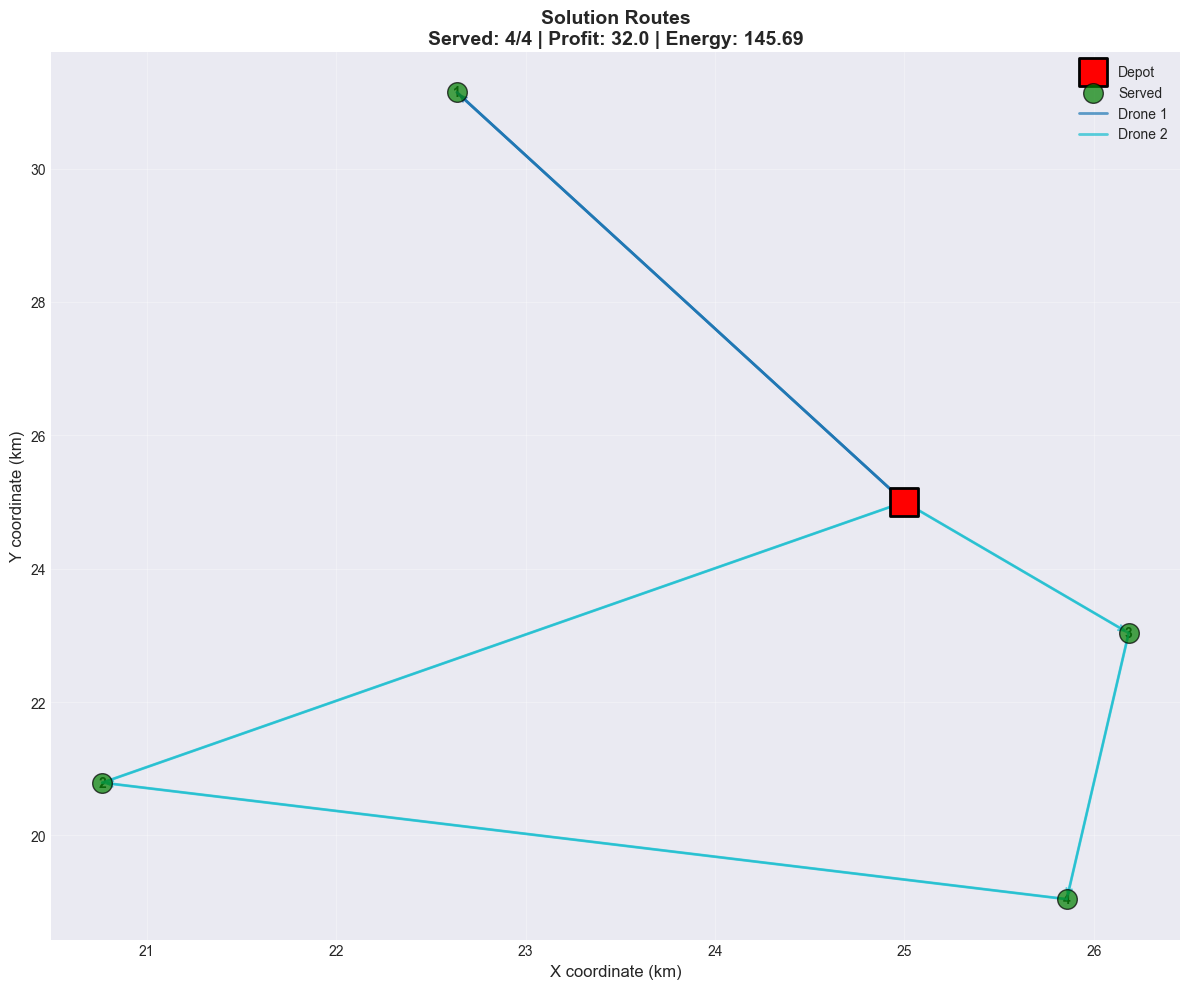


DETAILED SOLUTION

Drone 1:
  Trip 1: 0 → 1 → 0
    Energy consumed: 62.23
    Profit collected: 10.0
  Total energy (drone): 62.23
  Total profit (drone): 10.0

Drone 2:
  Trip 1: 0 → 3 → 4 → 2 → 0
    Energy consumed: 83.47
    Profit collected: 22.0
  Total energy (drone): 83.47
  Total profit (drone): 22.0

SUMMARY
Customers served: 4/4
Total profit: 32.00
Total energy: 145.69
Objective value: 145.69



In [10]:
"""
Test the MILP solver on a small, fully-feasible instance
"""
print("\n" + "="*70)
print("TESTING MILP SOLVER ON SMALL INSTANCE")
print("="*70)

# Build a small instance in the standard 50x50 service area and keep the
# top-priority customers (TOP pre-processing) so that serving the whole selected
# set is feasible under the battery limit, then build and solve the model.
np.random.seed(11)
small_feasible = preprocess_customer_selection(
    generator.generate_instance(num_customers=8, urgency_distribution='mixed'),
    config, k_max=4)
milp_small = DroneDeliveryMILP(small_feasible, config)
milp_small.build_model()
solution_small = milp_small.solve(time_limit=60)

if solution_small:
    milp_small.visualize_solution(solution_small)


In [11]:
"""
Implement nearest neighbor heuristic for initial feasible solution
Used as upper bound in Branch & Bound
"""
 
class NearestNeighborHeuristic:
    """Nearest Neighbor constructive heuristic for drone routing"""
    
    def __init__(self, instance: Dict, config: ProblemConfig):
        self.instance = instance
        self.config = config
        
    def solve(self, prioritize_urgency: bool = True) -> Dict:
        """
        Construct solution using nearest neighbor with urgency priority
        
        Args:
            prioritize_urgency: If True, sort by urgency first
            
        Returns:
            Solution dictionary
        """
        n = self.instance['num_customers']
        customers = list(range(1, n + 1))
        
        # Sort customers by urgency (descending) if prioritized
        if prioritize_urgency:
            urgencies = self.instance['urgencies']
            customers = sorted(customers, key=lambda i: urgencies[i-1], reverse=True)
        
        unvisited = set(customers)
        routes = {k: [] for k in range(1, self.config.num_drones + 1)}
        
        drone_batteries = {k: self.config.battery_capacity for k in range(1, self.config.num_drones + 1)}
        drone_trips = {k: 0 for k in range(1, self.config.num_drones + 1)}
        
        # Greedy assignment
        for customer in customers:
            if customer not in unvisited:
                continue
            
            # Try to assign to a drone
            assigned = False
            
            for k in range(1, self.config.num_drones + 1):
                # Check if can extend current route or start new trip
                current_route = routes[k]
                
                if not current_route or current_route[-1] == 0:
                    # Start new trip from depot
                    if drone_trips[k] >= self.config.max_trips_per_drone:
                        continue
                    
                    # Check energy feasibility: depot -> customer -> depot
                    energy_to = self.instance['energy_matrix'][0][customer]
                    energy_back = self.instance['energy_matrix'][customer][0]
                    
                    if energy_to + energy_back <= drone_batteries[k]:
                        # Feasible
                        routes[k].extend([0, customer] if not current_route else [customer])
                        drone_batteries[k] -= energy_to
                        unvisited.remove(customer)
                        assigned = True
                        break
                else:
                    # Extend current trip
                    last_customer = current_route[-1]
                    
                    # Check energy: current -> customer -> depot
                    energy_to = self.instance['energy_matrix'][last_customer][customer]
                    energy_back = self.instance['energy_matrix'][customer][0]
                    
                    if energy_to + energy_back <= drone_batteries[k]:
                        # Feasible
                        routes[k].append(customer)
                        drone_batteries[k] -= energy_to
                        unvisited.remove(customer)
                        assigned = True
                        break
            
            if not assigned:
                # Cannot assign this customer with current setup
                pass
        
        # Close all routes
        for k in routes:
            if routes[k] and routes[k][-1] != 0:
                routes[k].append(0)
        
        # Calculate solution metrics
        total_energy = 0
        total_profit = 0
        served_customers = []
        
        e = self.instance['energy_matrix']
        p = [0] + self.instance['urgencies']
        
        for k, route in routes.items():
            for i in range(len(route) - 1):
                from_node = route[i]
                to_node = route[i + 1]
                total_energy += e[from_node][to_node]
                
                if to_node > 0 and to_node not in served_customers:
                    served_customers.append(to_node)
                    total_profit += p[to_node]
        
        solution = {
            'routes': routes,
            'total_energy': total_energy,
            'total_profit': total_profit,
            'served_customers': served_customers,
            'num_served': len(served_customers),
            'objective_value': total_profit - self.config.lambda_weight * total_energy
        }
        
        return solution
 
 
print("✓ Nearest Neighbor heuristic defined")

✓ Nearest Neighbor heuristic defined


In [12]:
"""
Test the nearest neighbor heuristic
"""
 
print("\n" + "="*70)
print("TESTING NEAREST NEIGHBOR HEURISTIC")
print("="*70)
 
nn_heuristic = NearestNeighborHeuristic(small_instance, config)
nn_solution = nn_heuristic.solve(prioritize_urgency=True)
 
print(f"\nHeuristic Solution:")
print(f"  Customers served: {nn_solution['num_served']}/{small_instance['num_customers']}")
print(f"  Total profit: {nn_solution['total_profit']:.2f}")
print(f"  Total energy: {nn_solution['total_energy']:.2f}")
print(f"  Objective value: {nn_solution['objective_value']:.2f}")
 
for k, route in nn_solution['routes'].items():
    if len(route) > 0:
        print(f"  Drone {k}: {' → '.join(map(str, route))}")


TESTING NEAREST NEIGHBOR HEURISTIC

Heuristic Solution:
  Customers served: 5/5
  Total profit: 35.00
  Total energy: 0.00
  Objective value: 35.00
  Drone 1: 0 → 1 → 3 → 4 → 5 → 2 → 0


# Formulation 2 — Set-Partitioning (Route-Based)

Formulation 2 models the same problem at a different level of abstraction. Where Formulation 1
reasons at the **arc** level ($x_{ijk}$, with MTZ + big-M to assemble arcs into valid tours),
Formulation 2 reasons at the **route** level: we work with whole feasible trips as the decision
units. This is a different *abstraction level*, not an equivalent reformulation.

**Routes.** Let $R$ be the set of all *feasible single trips* (depot $\to$ ordered customers $\to$ depot).
A trip is feasible iff it respects payload ($\sum q_i \le Q$), battery (total trip energy $\le B$),
and uses only allowed arcs (no-fly zones excluded). For route $r$: $c_r$ = its energy,
$a_{ir} = 1$ if customer $i$ lies on route $r$.

**Decision variables.** $y_r \in \{0,1\}$ — 1 if route $r$ is selected.

**Model (classical set-partitioning, Balinski & Quandt 1964):**

$$\min \sum_{r\in R} c_r\, y_r$$

$$\text{s.t.}\quad \sum_{r\in R} a_{ir}\, y_r = 1 \quad \forall i \in N \qquad\text{(each selected customer covered exactly once)}$$

$$\sum_{r\in R} y_r \le m \cdot R_{\max} \qquad\text{(fleet / trip-slot limit)}$$

$$y_r \in \{0,1\}$$

**Selective (TOP) variant.** Replacing $=1$ by $\le 1$ turns this into a set-covering / packing model
that selects the most profitable subset of customers — the natural orienteering reading.

**A different level of abstraction.** Feasibility (battery, payload, no-fly,
subtour-freeness) is enforced when each column is *generated*, so the model contains **no big-M and
no MTZ**. The two formulations differ in variables, size (polynomial vs. exponential number of
columns), and LP-relaxation strength — so they are not equivalent reformulations.

**Exactness on our instances.** After preprocessing, instances have few customers, so we can
**enumerate all feasible routes exactly** (no column generation needed). For each customer subset that
fits the payload, we keep the cheapest battery/no-fly-feasible depot tour (a tiny TSP). This yields an
exact set-partitioning model whose optimum must equal Formulation 1's optimum.


In [13]:
"""
Formulation 2: Set-Partitioning (route-based) for the drone delivery problem.
A 'route' = one feasible single trip (depot -> ordered customers -> depot).
Different abstraction from F1: variables are whole routes, not arcs.
Exact for small instances via full subset enumeration (no big-M, no MTZ).
"""
import itertools
import numpy as np
from pulp import (LpProblem, LpMinimize, LpVariable, LpBinary, lpSum,
                  PULP_CBC_CMD, LpStatus, value, LpStatusOptimal)


def _best_trip_over_subset(subset, e, fa, B):
    """Min-energy feasible depot tour visiting exactly `subset` (a tuple of customer ids).
    Returns (best_energy, best_order) or (None, None) if no battery/arc-feasible ordering."""
    best_e = None
    best_order = None
    for perm in itertools.permutations(subset):
        seq = [0] + list(perm) + [0]
        # arc feasibility (no-fly) + accumulate energy
        ok = True
        energy = 0.0
        for a, b in zip(seq, seq[1:]):
            if fa is not None and not fa[a][b]:
                ok = False
                break
            energy += e[a][b]
        if not ok:
            continue
        if energy > B:          # battery: total trip energy <= B (monotone, positive arcs)
            continue
        if best_e is None or energy < best_e:
            best_e = energy
            best_order = perm
    return best_e, best_order


def enumerate_routes(instance, config):
    """Enumerate all feasible single-trip routes (one cheapest route per covered subset)."""
    n = instance['num_customers']
    e = instance['energy_matrix']
    q = [0] + list(instance['demands'])
    fa = instance.get('feasible_arc')
    B = config.battery_capacity
    Q = config.payload_capacity

    routes = []   # each: dict(subset=frozenset, order=tuple, energy=float)
    customers = list(range(1, n + 1))
    for size in range(1, n + 1):
        for subset in itertools.combinations(customers, size):
            if sum(q[i] for i in subset) > Q:          # payload prune
                continue
            be, order = _best_trip_over_subset(subset, e, fa, B)
            if be is None:
                continue
            routes.append({'subset': frozenset(subset), 'order': order, 'energy': be})
    return routes


class SetPartitioningModel:
    """Formulation 2: route-based set-partitioning MILP."""
    def __init__(self, instance, config):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']
        self.max_routes = config.num_drones * int(getattr(config, 'max_trips_per_drone', 1))
        self.routes = None
        self.model = None

    def build_model(self):
        self.routes = enumerate_routes(self.instance, self.config)
        R = self.routes
        n = self.n
        if not R:
            raise ValueError("No feasible routes enumerated (check B/Q/no-fly).")

        self.model = LpProblem("SetPartitioning_Drone", LpMinimize)
        y = LpVariable.dicts("y", range(len(R)), 0, 1, LpBinary)
        self.y = y

        # Objective: minimize total energy (serve-all => same objective as F1)
        self.model += lpSum(R[r]['energy'] * y[r] for r in range(len(R))), "Total_Energy"

        # Each selected customer covered exactly once (partitioning)
        for i in range(1, n + 1):
            self.model += lpSum(y[r] for r in range(len(R)) if i in R[r]['subset']) == 1, f"Cover_{i}"

        # Fleet limit: at most m*R routes (trip slots)
        self.model += lpSum(y[r] for r in range(len(R))) <= self.max_routes, "Fleet_Limit"

        print(f"Set-Partitioning: {len(R)} feasible route-columns, {n} customers, <= {self.max_routes} routes")
        return self

    def solve(self, time_limit=300, msg=0):
        solver = PULP_CBC_CMD(timeLimit=time_limit, msg=msg)
        self.model.solve(solver)
        status = LpStatus[self.model.status]
        if self.model.status != LpStatusOptimal:
            return {'status': status, 'total_energy': None}
        chosen = [r for r in range(len(self.routes)) if value(self.y[r]) > 0.5]
        total_energy = sum(self.routes[r]['energy'] for r in chosen)
        trips = [[0] + list(self.routes[r]['order']) + [0] for r in chosen]
        return {'status': status, 'total_energy': total_energy,
                'num_routes': len(chosen), 'trips': trips}


## Validation — Formulation 2 optimum must equal Formulation 1 optimum

If the two models describe the same problem, the **set-partitioning optimum must match the
arc-based MILP optimum** on every instance. This is the correctness proof for F2 and the evidence
for the "two formulations of the same problem" requirement.


In [14]:
# Validate F2 (set-partitioning) optimum == F1 (arc-based MILP) optimum
import numpy as np

_val_cfg = ProblemConfig()
_val_cfg.max_trips_per_drone = 2   # keep the arc-based MILP light for this check

print(f"{'seed':>5} {'F1_arc':>12} {'F2_setpart':>12} {'MATCH':>7}")
_all_match = True
for _seed in [11, 22, 33, 44, 55]:
    np.random.seed(_seed)
    _gen = InstanceGenerator(_val_cfg)
    _inst = _gen.generate_instance(8)
    _pp = preprocess_customer_selection(_inst, _val_cfg, k_max=5)

    _milp = DroneDeliveryMILP(_pp, _val_cfg); _milp.build_model()
    _s1 = _milp.solve(time_limit=60)
    _e1 = _s1['total_energy'] if _s1 else None

    _sp = SetPartitioningModel(_pp, _val_cfg).build_model()
    _s2 = _sp.solve(time_limit=60)
    _e2 = _s2['total_energy']

    _m = (_e1 is not None and _e2 is not None and abs(_e1 - _e2) < 1e-3)
    _all_match = _all_match and _m
    print(f"{_seed:>5} {(_e1 if _e1 is not None else float('nan')):>12.4f} "
          f"{(_e2 if _e2 is not None else float('nan')):>12.4f} {str(_m):>7}")

print("ALL INSTANCES MATCH:", _all_match)


 seed       F1_arc   F2_setpart   MATCH

PREPROCESSING: Customer Selection (TOP Element)
Original customers: 8
Selected customers (K_max): 5
Selection rate: 62.5%
Selected customer IDs: [np.int64(2), np.int64(4), np.int64(7), np.int64(6), np.int64(8)]
Total urgency of selected: 38.0
Total urgency of all: 53.0
Urgency captured: 71.7%

Building MILP model for 5 customers, 2 drones, up to 2 trips/drone (V=4)...
✓ Model built successfully: 208 variables, 414 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 60 seconds

SOLUTION STATUS: Optimal
Solve time: 3.76 seconds
Objective value: 158.48
Set-Partitioning: 14 feasible route-columns, 5 customers, <= 4 routes
   11     158.4774     158.4774    True

PREPROCESSING: Customer Selection (TOP Element)
Original customers: 8
Selected customers (K_max): 5
Selection rate: 62.5%
Selected customer IDs: [np.int64(2), np.int64(4), np.int64(6), np.int64(5), np.int64(7)]
Total urgency of selected: 37.0
Total urgency of all: 51.0
Urgency cap

# Exact Method — Custom Branch & Bound (Arc-Based)

The project requires an exact method (Branch & Bound recommended). We implement a **custom**
Branch & Bound *framework* over Formulation 1's arc variables, using an LP/MILP solver only to
solve the **LP relaxation at each node** (as opposed to handing the whole problem to the solver's
built-in black-box B&B):

- **Lower bound:** the LP relaxation of F1 at the node (binaries `x`, `visit` relaxed to `[0,1]`).
- **Upper bound (incumbent):** the Nearest-Neighbor heuristic, *used only if it is fully feasible*.
- **Branching:** on the most-fractional arc `x_{ijv}` (closest to 0.5).
- **Node selection:** best-first (priority queue ordered by the LP lower bound).
- **Pruning:** by bound (`LP ≥ incumbent`) and by LP-infeasibility.

**Big-M safeguard.** Because the formulation uses a large `M`, an LP solution can sit at
`x = 0.999999` and gain `M·(1−x) ≈ 0.1` of slack on the battery/payload constraints — enough to
make an *infeasible* routing look integral. We check true feasibility (serve-all +
battery + payload + no-fly) at every integer leaf and discard points that are feasible only because of big-M slack, forcing more
branching rather than accepting an infeasible solution.


In [15]:
"""
Custom Branch & Bound on the arc-based model (Formulation 1).
Design:
  - solve the LP relaxation at each node with PuLP/CBC (LP solver only)
  - branch on the most-fractional arc x_ijv
  - best-first node selection (priority queue on the LP lower bound)
  - incumbent (upper bound) updated ONLY from a fully feasible solution:
      * the Nearest-Neighbor seed is used only if it is verified feasible (serve-all + battery/payload/no-fly)
      * otherwise from integral-x LP leaves (which satisfy every MILP constraint)
  - prune by bound and by LP-infeasibility
"""
import heapq, time, io, contextlib
from pulp import LpContinuous, PULP_CBC_CMD, value, LpStatusOptimal


def route_feasible_serve_all(routes, instance, config, tol=1e-6):
    """Full feasibility: serve every customer exactly once, and every trip respects
    battery (total trip energy <= B), payload (sum demand <= Q), and allowed arcs."""
    n = instance['num_customers']
    e = instance['energy_matrix']
    d = [0] + list(instance['demands'])
    fa = instance.get('feasible_arc')
    B, Q = config.battery_capacity, config.payload_capacity
    served = []
    for route in routes.values():
        trip = []
        def check(trip_nodes):
            if not trip_nodes:
                return True
            seq = [0] + trip_nodes + [0]
            energy = 0.0
            for a, b in zip(seq, seq[1:]):
                if fa is not None and not fa[a][b]:
                    return False
                energy += e[a][b]
            if energy > B + tol:
                return False
            if sum(d[c] for c in trip_nodes) > Q + tol:
                return False
            return True
        for node in route:
            if node == 0:
                if not check(trip):
                    return False
                trip = []
            else:
                trip.append(node); served.append(node)
        if not check(trip):
            return False
    return sorted(served) == list(range(1, n + 1))


class _BBNode:
    _ctr = 0
    def __init__(self, fixed, lb, depth):
        self.fixed, self.lb, self.depth = fixed, lb, depth
        _BBNode._ctr += 1
        self.id = _BBNode._ctr
    def __lt__(self, other):
        return (self.lb, self.id) < (other.lb, other.id)


class CustomBranchAndBoundArc:
    def __init__(self, instance, config, time_limit=60, node_limit=20000, tol=1e-6):
        self.instance, self.config = instance, config
        self.time_limit, self.node_limit, self.tol = time_limit, node_limit, tol
        self.incumbent = float('inf')
        self.best_x = None
        self.nodes_explored = 0
        self.lp_solver = PULP_CBC_CMD(msg=0)

    def _solve_lp(self, fixed):
        """Build F1, relax ALL binaries to [0,1], apply branch fixings, solve the LP."""
        milp = DroneDeliveryMILP(self.instance, self.config)
        with contextlib.redirect_stdout(io.StringIO()):
            milp.build_model()
        x = milp.variables['x']
        # Relax the integer/binary decision variables (x, visit) to [0,1].
        # NOTE: in this PuLP version binary vars report cat == 'Integer', so we relax
        # the known binary dictionaries explicitly rather than matching on cat strings.
        for dict_name in ('x', 'visit'):
            for var in milp.variables.get(dict_name, {}).values():
                var.cat = LpContinuous
                var.lowBound, var.upBound = 0, 1
        for key, val in fixed.items():
            if key in x:
                x[key].lowBound = x[key].upBound = val
        with contextlib.redirect_stdout(io.StringIO()):
            milp.model.solve(self.lp_solver)
        if milp.model.status != LpStatusOptimal:
            return None, None
        obj = value(milp.model.objective)
        xval = {k: (value(v) or 0.0) for k, v in x.items()}
        return obj, xval

    def _most_fractional(self, xval):
        best_key, best_frac = None, self.tol
        for k, v in xval.items():
            f = min(v, 1 - v)
            if f > best_frac:
                best_frac, best_key = f, k
        return best_key

    def _routes_from_x(self, xval):
        """Reconstruct drone routes from an integral x solution (for feasibility check)."""
        R = int(self.config.max_trips_per_drone)
        chosen = {k for k, v in xval.items() if v > 0.5}
        out = {}
        for (i, j, v) in chosen:
            out.setdefault(v, {})[i] = j
        routes = {k: [] for k in range(1, self.config.num_drones + 1)}
        for v, adj in out.items():
            if 0 not in adj:
                continue
            seq, cur = [0], 0
            for _ in range(self.instance['num_customers'] + 2):
                nxt = adj.get(cur)
                if nxt is None:
                    break
                seq.append(nxt); cur = nxt
                if cur == 0:
                    break
            drone = (v - 1) // R + 1
            routes[drone].extend(seq if not routes[drone] else seq)
        return routes

    def solve(self, verbose=False, use_nn_seed=True):
        t0 = time.time()
        # Optional NN seed — used ONLY if fully feasible
        if use_nn_seed:
            nn = NearestNeighborHeuristic(self.instance, self.config).solve()
            if nn and route_feasible_serve_all(nn['routes'], self.instance, self.config):
                self.incumbent = nn['total_energy']
                if verbose: print(f"NN seed feasible -> incumbent {self.incumbent:.3f}")

        root_obj, root_x = self._solve_lp({})
        if root_obj is None:
            return {'status': 'Infeasible', 'energy': None, 'nodes': 0}
        pq = [_BBNode({}, root_obj, 0)]
        cache = {pq[0].id: root_x}

        while pq:
            if time.time() - t0 > self.time_limit or self.nodes_explored >= self.node_limit:
                break
            node = heapq.heappop(pq)
            self.nodes_explored += 1
            if node.lb >= self.incumbent - self.tol:        # prune by bound
                continue
            xval = cache.pop(node.id, None)
            if xval is None:
                obj, xval = self._solve_lp(node.fixed)
                if obj is None:                              # LP infeasible
                    continue
                node.lb = obj
                if node.lb >= self.incumbent - self.tol:
                    continue
            frac = self._most_fractional(xval)
            if frac is None:
                # LP reports an integer solution; big-M can mask violations, so re-check true feasibility.
                rounded = {k: (1 if v > 0.5 else 0) for k, v in xval.items()}
                routes = self._routes_from_x(rounded)
                if route_feasible_serve_all(routes, self.instance, self.config):
                    if node.lb < self.incumbent - self.tol:   # genuine feasible incumbent
                        self.incumbent, self.best_x = node.lb, xval
                        if verbose: print(f"  incumbent {self.incumbent:.3f} @ node {self.nodes_explored}")
                    continue
                # feasible only via big-M slack: discard this point and branch further
                frac = next((k for k, v in rounded.items()
                             if v == 1 and k not in node.fixed), None)
                if frac is None:
                    continue                                  # nothing left to branch -> discard
            for val in (1, 0):                               # branch
                child_fixed = dict(node.fixed); child_fixed[frac] = val
                obj, cx = self._solve_lp(child_fixed)
                if obj is None or obj >= self.incumbent - self.tol:
                    continue
                child = _BBNode(child_fixed, obj, node.depth + 1)
                heapq.heappush(pq, child)
                cache[child.id] = cx

        proven = (len(pq) == 0)
        return {'status': 'Optimal' if proven else 'Stopped (limit)',
                'energy': (self.incumbent if self.incumbent < float('inf') else None),
                'nodes': self.nodes_explored}


## Validation — Branch & Bound vs MILP vs Set-Partitioning

In [16]:
# Validation — custom B&B vs exact MILP (CBC) vs Set-Partitioning (F2)
# On small instances the three exact approaches return the same optimum; the node
# counts show the B&B explores a search tree (not just the root), and it proves
# optimality in well under a second per instance.
import numpy as np, io, contextlib, time

_bb_cfg = ProblemConfig(); _bb_cfg.max_trips_per_drone = 1; _bb_cfg.bnb_gap_tolerance = 0.0
print(f"{'seed':>5} {'CBC(F1)':>9} {'F2':>9} {'B&B':>9} {'nodes':>6} {'sec':>6} {'MATCH':>6}")
_ok = True
for _seed in [11, 22, 33, 44, 55]:
    np.random.seed(_seed)
    with contextlib.redirect_stdout(io.StringIO()):
        _inst = InstanceGenerator(_bb_cfg).generate_instance(6)
        _pp = preprocess_customer_selection(_inst, _bb_cfg, k_max=3)
        _m = DroneDeliveryMILP(_pp, _bb_cfg); _m.build_model()
        _s1 = _m.solve(time_limit=60); _e1 = _s1['total_energy'] if _s1 else None
        _e2 = SetPartitioningModel(_pp, _bb_cfg).build_model().solve()['total_energy']
        _t0 = time.time()
        _r = CustomBranchAndBoundArc(_pp, _bb_cfg, time_limit=60).solve(use_nn_seed=False)
        _dt = time.time() - _t0
        _e3 = _r['energy']
    _vals = [v for v in (_e1, _e2, _e3) if v is not None]
    _m_ok = (len(_vals) == 0) or (len(_vals) == 3 and max(_vals) - min(_vals) < 1e-2)
    _ok = _ok and _m_ok
    _f = lambda v: f"{v:9.3f}" if v is not None else "     None"
    print(f"{_seed:>5} {_f(_e1)} {_f(_e2)} {_f(_e3)} {_r['nodes']:>6} {_dt:>6.1f} {str(_m_ok):>6}")
print("\nAll three methods agree:", _ok)


 seed   CBC(F1)        F2       B&B  nodes    sec  MATCH
   11    77.640    77.640    77.640     25    2.1   True
   22   117.254   117.254   117.254     32    4.1   True
   33   119.498   119.498   119.498     40    5.5   True
   44   142.013   142.013   142.013     38    5.0   True
   55    99.783    99.783    99.783     18    1.5   True

All three methods agree: True


# Metaheuristic Development


## Solution Encoding
We decide on how the solution is represented in memory because every operator (crossover, Mutatation) works on this presentation.
*the chosen encoding here is route-list representation*

In [17]:
solution = {
    1: [0, 4, 5, 6, 7, 0],
    2: [0, 3, 0, 0, 1, 2, 0] 
}

In [18]:
def evaluate_route(route, instance, config):
    """Evaluate a single drone route.

    Route encoding:
    - `0` is the depot.
    - Multiple trips are separated by depot visits (i.e., additional `0`s).

    Returns:
        (total_energy, total_profit)
    """
    e = instance["energy_matrix"]

    # Urgency/profit is defined only for customers 1..n.
    p = [0] + instance["urgencies"]

    total_energy = 0.0
    total_profit = 0.0

    # Avoid double-counting the same customer within the same route.
    served = set()

    for i in range(len(route) - 1):
        src = route[i]
        dst = route[i + 1]

        total_energy += e[src][dst]

        if dst > 0 and dst not in served:
            total_profit += p[dst]
            served.add(dst)

    return total_energy, total_profit


In [19]:
def evaluate(solution, instance, config):
    total_energy = 0
    total_profit = 0
    for drone_id, route in solution.items():
        energy, profit = evaluate_route(route, instance, config)
        total_energy += energy
        total_profit += profit

    return total_energy, total_profit


## Metaheuristic 1 Genetic Algorithm

In [20]:
import random
import copy
import numpy as np
from typing import List, Dict, Tuple

class GeneticAlgorithm:
    """
    Population-based metaheuristic for drone delivery optimization.
    Operates on Formulation 1's route structure.
    """
    
    def __init__(self, instance: Dict, config, 
                 population_size: int = 80,
                 generations: int = 200,
                 crossover_rate: float = 0.85,
                 mutation_rate: float = 0.20,
                 elite_size: int = 7,
                 tournament_size: int = 7):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']
        self.m = config.num_drones
        self.R = config.max_trips_per_drone
        self.pop_size = population_size
        self.generations = generations
        self.cx_rate = crossover_rate
        self.mut_rate = mutation_rate
        self.elite_size = elite_size
        self.tournament_size = tournament_size
        
        # Tracking
        self.best_solution = None
        self.best_fitness = float('inf')
        self.fitness_history = []
        
    # INITIALIZATION
    
    def initialize_population(self) -> List[Dict]:
        """
        Generate initial population using a mix of:
        - Nearest-neighbor heuristic (1 individual) for a quality seed
        - Random shuffles of the customer list (rest)
        This balances quality initialization with diversity.
        """
        population = []
        
        # Seed with nearest-neighbor solution
        nn = NearestNeighborHeuristic(self.instance, self.config)
        nn_sol = nn.solve()
        population.append(nn_sol['routes'])
        
        # Fill the rest with random solutions
        customers = list(range(1, self.n + 1))
        for _ in range(self.pop_size - 1):
            random.shuffle(customers)
            individual = self._customers_to_routes(customers)
            population.append(individual)
        
        return population
    
    def _customers_to_routes(self, customer_order: List[int]) -> Dict:
        """
        Convert a flat customer permutation into drone routes,
        distributing customers greedily while respecting battery + payload.
        This is the 'split' algorithm adapted from the giant-tour literature.
        """
        routes = {k: [0] for k in range(1, self.m + 1)}
        batteries = {k: self.config.battery_capacity for k in range(1, self.m + 1)}
        payloads = {k: 0.0 for k in range(1, self.m + 1)}
        trip_counts = {k: 1 for k in range(1, self.m + 1)}
        
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']  # index 0 = depot
        
        for customer in customer_order:
            assigned = False
            
            # Try to extend an existing route on any drone
            for k in range(1, self.m + 1):
                last = routes[k][-1]
                energy_to = e[last][customer]
                energy_back = e[customer][0]
                new_payload = payloads[k] + demands[customer]
                
                if (batteries[k] - energy_to - energy_back >= 0 and
                        new_payload <= self.config.payload_capacity):
                    routes[k].append(customer)
                    batteries[k] -= energy_to
                    payloads[k] = new_payload
                    assigned = True
                    break
            
            if not assigned:
                # Try to start a new trip on any drone with capacity left
                for k in range(1, self.m + 1):
                    if trip_counts[k] >= self.R:
                        continue
                    energy_to = e[0][customer]
                    energy_back = e[customer][0]
                    if (energy_to + energy_back <= self.config.battery_capacity and
                            demands[customer] <= self.config.payload_capacity):
                        routes[k].append(0)  # return to depot
                        routes[k].append(customer)
                        batteries[k] = self.config.battery_capacity - energy_to
                        payloads[k] = demands[customer]
                        trip_counts[k] += 1
                        assigned = True
                        break
            
            # If still unassigned, append to least-loaded drone (will be repaired)
            if not assigned:
                k = min(range(1, self.m + 1), key=lambda x: len(routes[x]))
                routes[k].append(customer)
        
        # Close all routes
        for k in range(1, self.m + 1):
            if routes[k][-1] != 0:
                routes[k].append(0)
        
        return routes
    
    # FITNESS EVALUATION
    
    def fitness(self, individual: Dict) -> float:
        """
        Fitness = total energy consumed (lower is better).
        We add a large penalty for infeasible solutions to guide repair.
        """
        total_energy = 0.0
        penalty = 0.0
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        customers_served = set()
        
        for k, route in individual.items():
            battery = self.config.battery_capacity
            payload = 0.0
            
            for i in range(len(route) - 1):
                src, dst = route[i], route[i + 1]
                energy_step = e[src][dst]
                total_energy += energy_step
                battery -= energy_step
                
                if dst != 0:
                    payload += demands[dst]
                    customers_served.add(dst)
                else:
                    payload = 0.0  # reload at depot
                
                if battery < 0:
                    penalty += abs(battery) * 100
                if payload > self.config.payload_capacity:
                    penalty += (payload - self.config.payload_capacity) * 100
        
        # Penalty for missing customers
        all_customers = set(range(1, self.n + 1))
        missing = all_customers - customers_served
        penalty += len(missing) * 1000
        
        return total_energy + penalty
    
    # SELECTION — Tournament
    
    def tournament_selection(self, population: List[Dict], 
                              fitnesses: List[float]) -> Dict:
        """
        Tournament selection: pick T random individuals, return the best.
        Balances selection pressure with diversity preservation.
        A tournament size around 5 balances selection pressure 
        against population diversity.
        """
        indices = random.sample(range(len(population)), self.tournament_size)
        best_idx = min(indices, key=lambda i: fitnesses[i])
        return copy.deepcopy(population[best_idx])
    
    # CROSSOVER — Order Crossover adapted for routes (OX)
    
    def crossover(self, parent1: Dict, parent2: Dict) -> Tuple[Dict, Dict]:
        """
        Route-aware Order Crossover (OX):
        1. Extract the flat customer visit order from each parent (ignoring depot 0s)
        2. Apply OX on the customer sequences
        3. Reconstruct routes from the new sequences using the split algorithm
        
        Order crossover preserves the relative order of customers from one parent,
        which encodes spatial adjacency information. A customer that tends to 
        appear right before another in high-quality solutions will keep that 
        adjacency in the offspring.
        """
        if random.random() > self.cx_rate:
            return copy.deepcopy(parent1), copy.deepcopy(parent2)
        
        # Extract customer sequences (no depot visits)
        raw_seq1 = [c for route in parent1.values() for c in route if c != 0]
        raw_seq2 = [c for route in parent2.values() for c in route if c != 0]

        # Normalize to valid permutations of 1..n (remove duplicates, append missing).
        # This prevents OX from crashing when parents are temporarily infeasible.
        all_customers = list(range(1, self.n + 1))

        def normalize(seq):
            seen = set()
            cleaned = []
            for x in seq:
                if x in seen:
                    continue
                if 1 <= x <= self.n:
                    cleaned.append(x)
                    seen.add(x)
            missing = [c for c in all_customers if c not in seen]
            random.shuffle(missing)
            return cleaned + missing

        seq1 = normalize(raw_seq1)
        seq2 = normalize(raw_seq2)

        n = self.n
        if n < 2:
            return copy.deepcopy(parent1), copy.deepcopy(parent2)

        # OX: choose two random cut points
        a, b = sorted(random.sample(range(n), 2))

        def ox(s1, s2):
            child = [None] * n
            # Copy the segment from s1 directly
            child[a:b+1] = s1[a:b+1]
            # Fill remaining positions with s2's order, skipping already-placed
            segment_set = set(s1[a:b+1])
            remaining = [x for x in s2 if x not in segment_set]
            ptr = 0
            for i in list(range(b+1, n)) + list(range(0, a)):
                child[i] = remaining[ptr]
                ptr += 1
            return child

        child_seq1 = ox(seq1, seq2)
        child_seq2 = ox(seq2, seq1)
        
        child1 = self._customers_to_routes(child_seq1)
        child2 = self._customers_to_routes(child_seq2)
        
        return child1, child2
    
    # MUTATION
    
    def mutate(self, individual: Dict) -> Dict:
        """
        Three problem-specific mutation operators, each triggered with 
        probability mut_rate:
        
        M1 - Intra-route 2-opt: reverse a sub-segment within one drone's route.
             Improves route geometry (eliminates crossing paths).
        M2 - Inter-route relocate: move one customer from one drone to another.
             Balances load between drones.
        M3 - Intra-route swap: exchange two customers within the same route.
             Fine-grained local improvement.
        """
        ind = copy.deepcopy(individual)
        
        op = random.random()
        
        if op < 0.4:
            # M1: 2-opt within a random drone's route
            k = random.choice(list(ind.keys()))
            customers_in_route = [c for c in ind[k] if c != 0]
            if len(customers_in_route) >= 2:
                i, j = sorted(random.sample(range(len(customers_in_route)), 2))
                customers_in_route[i:j+1] = customers_in_route[i:j+1][::-1]
                ind[k] = self._rebuild_route(customers_in_route, k)
        
        elif op < 0.7:
            # M2: relocate a customer from one drone to another
            drones = list(ind.keys())
            if len(drones) >= 2:
                k1, k2 = random.sample(drones, 2)
                customers_k1 = [c for c in ind[k1] if c != 0]
                if customers_k1:
                    customer = random.choice(customers_k1)
                    customers_k1.remove(customer)
                    customers_k2 = [c for c in ind[k2] if c != 0]
                    insert_pos = random.randint(0, len(customers_k2))
                    customers_k2.insert(insert_pos, customer)
                    ind[k1] = self._rebuild_route(customers_k1, k1)
                    ind[k2] = self._rebuild_route(customers_k2, k2)
        
        else:
            # M3: swap two customers within one route
            k = random.choice(list(ind.keys()))
            customers_in_route = [c for c in ind[k] if c != 0]
            if len(customers_in_route) >= 2:
                i, j = random.sample(range(len(customers_in_route)), 2)
                customers_in_route[i], customers_in_route[j] = \
                    customers_in_route[j], customers_in_route[i]
                ind[k] = self._rebuild_route(customers_in_route, k)
        
        return ind
    
    def _rebuild_route(self, customers: List[int], drone_id: int) -> List[int]:
        """Reconstruct a route list with depot markers from a flat customer list."""
        return self._customers_to_routes(customers)[drone_id] if customers else [0, 0]
    
    # REPAIR
    
    def repair(self, individual: Dict) -> Dict:
        """
        Ensure every customer appears exactly once.
        - Remove duplicates (keep the first occurrence)
        - Insert missing customers at the cheapest feasible position
        """
        all_customers = set(range(1, self.n + 1))
        seen = set()
        
        # Pass 1: remove duplicates
        for k in individual:
            new_route = []
            for c in individual[k]:
                if c == 0 or c not in seen:
                    new_route.append(c)
                    if c != 0:
                        seen.add(c)
            individual[k] = new_route
        
        # Pass 2: insert missing customers at cheapest position
        missing = list(all_customers - seen)
        e = self.instance['energy_matrix']
        
        for customer in missing:
            best_delta = float('inf')
            best_k, best_pos = 1, 1
            
            for k, route in individual.items():
                customers_only = [c for c in route if c != 0]
                for pos in range(len(customers_only) + 1):
                    new_seq = customers_only[:pos] + [customer] + customers_only[pos:]
                    delta = self._insertion_cost(customer, pos, customers_only, e)
                    if delta < best_delta:
                        best_delta = delta
                        best_k, best_pos = k, pos
            
            customers_only = [c for c in individual[best_k] if c != 0]
            customers_only.insert(best_pos, customer)
            individual[best_k] = self._customers_to_routes(customers_only)[best_k]
        
        return individual
    
    def _insertion_cost(self, customer, pos, sequence, energy_matrix):
        if not sequence:
            return energy_matrix[0][customer] + energy_matrix[customer][0]
        prev = sequence[pos-1] if pos > 0 else 0
        next_ = sequence[pos] if pos < len(sequence) else 0
        return (energy_matrix[prev][customer] + energy_matrix[customer][next_] 
                - energy_matrix[prev][next_])
    
    # MAIN LOOP
    
    def solve(self) -> Dict:
        import time
        start = time.time()
        
        population = self.initialize_population()
        fitnesses = [self.fitness(ind) for ind in population]
        
        best_idx = np.argmin(fitnesses)
        self.best_solution = copy.deepcopy(population[best_idx])
        self.best_fitness = fitnesses[best_idx]
        
        print(f"GA initial best fitness: {self.best_fitness:.2f}")
        
        for gen in range(self.generations):
            new_population = []
            
            # Elitism: carry forward the best individuals unchanged
            elite_indices = np.argsort(fitnesses)[:self.elite_size]
            for idx in elite_indices:
                new_population.append(copy.deepcopy(population[idx]))
            
            # Fill the rest of the population
            while len(new_population) < self.pop_size:
                p1 = self.tournament_selection(population, fitnesses)
                p2 = self.tournament_selection(population, fitnesses)
                c1, c2 = self.crossover(p1, p2)
                c1 = self.mutate(c1)
                c2 = self.mutate(c2)
                c1 = self.repair(c1)
                c2 = self.repair(c2)
                new_population.extend([c1, c2])
            
            population = new_population[:self.pop_size]
            fitnesses = [self.fitness(ind) for ind in population]
            
            gen_best = min(fitnesses)
            self.fitness_history.append(gen_best)
            
            if gen_best < self.best_fitness:
                self.best_fitness = gen_best
                self.best_solution = copy.deepcopy(
                    population[np.argmin(fitnesses)])
                print(f"  Gen {gen+1}: New best = {self.best_fitness:.2f}")
            
            if (gen + 1) % 50 == 0:
                elapsed = time.time() - start
                print(f"  Gen {gen+1}/{self.generations} | "
                      f"Best: {self.best_fitness:.2f} | "
                      f"Time: {elapsed:.1f}s")
        
        print(f"\nGA finished. Best energy: {self.best_fitness:.2f}")
        return self.best_solution

In [21]:
import math
import time

class SimulatedAnnealing:
    """
    Single-solution local search metaheuristic for drone delivery.
    Complements the GA by providing deep exploitation from a good initial solution.
    """
    
    def __init__(self, instance: Dict, config,
                 T_initial: float = 50.0,
                 T_final: float = 0.05,
                 alpha: float = 0.97,
                 iterations_per_temp: int = 100,
                 time_limit: float = 120.0):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']
        self.m = config.num_drones
        self.T_initial = T_initial
        self.T_final = T_final
        self.alpha = alpha
        self.iters = iterations_per_temp
        self.time_limit = time_limit
        
        # Tracking
        self.best_solution = None
        self.best_energy = float('inf')
        self.energy_history = []
        self.acceptance_history = []
    
    # ------------------------------------------------------------------ #
    # 1. ENERGY EVALUATION (objective)
    # ------------------------------------------------------------------ #
    
    def evaluate(self, solution: Dict) -> float:
        """
        Compute total routing energy for a solution.
        Adds heavy penalty for constraint violations so that the SA
        can cross infeasible regions briefly to reach better feasible solutions.
        """
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        total_energy = 0.0
        penalty = 0.0
        customers_served = set()
        
        for k, route in solution.items():
            battery = self.config.battery_capacity
            payload = 0.0
            
            for i in range(len(route) - 1):
                src, dst = route[i], route[i+1]
                step = e[src][dst]
                total_energy += step
                battery -= step
                
                if dst == 0:
                    payload = 0.0
                else:
                    payload += demands[dst]
                    customers_served.add(dst)
                
                if battery < -1e-6:
                    penalty += abs(battery) * 50
                if payload > self.config.payload_capacity + 1e-6:
                    penalty += (payload - self.config.payload_capacity) * 50
        
        missing = len(set(range(1, self.n + 1)) - customers_served)
        penalty += missing * 500
        
        return total_energy + penalty
    
    # ------------------------------------------------------------------ #
    # 2. NEIGHBORHOOD OPERATORS
    # ------------------------------------------------------------------ #
    
    def _get_route_customers(self, route: List[int]) -> List[int]:
        return [c for c in route if c != 0]
    
    def _rebuild_with_depots(self, customers: List[int], 
                              drone_id: int, ga: GeneticAlgorithm) -> List[int]:
        """Reconstruct route with depot delimiters respecting battery/payload."""
        sol = ga._customers_to_routes(customers)
        return sol.get(drone_id, [0, 0])
    
    def neighbor_2opt_intra(self, solution: Dict) -> Dict:
        """
        N1: 2-opt within a single drone's route.
        Reverses a contiguous sub-segment of customers.
        Eliminates crossing paths — the most common source of inefficiency
        in greedy-constructed routes.
        """
        neighbor = copy.deepcopy(solution)
        k = random.choice(list(neighbor.keys()))
        customers = self._get_route_customers(neighbor[k])
        
        if len(customers) < 2:
            return neighbor
        
        i, j = sorted(random.sample(range(len(customers)), 2))
        customers[i:j+1] = customers[i:j+1][::-1]
        
        # Reconstruct with battery-aware trip splits
        new_route = [0]
        battery = self.config.battery_capacity
        payload = 0.0
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        
        current_pos = 0
        for customer in customers:
            e_to = e[current_pos][customer]
            e_back = e[customer][0]
            new_payload = payload + demands[customer]
            
            if (battery - e_to - e_back >= 0 and 
                    new_payload <= self.config.payload_capacity):
                new_route.append(customer)
                battery -= e_to
                payload = new_payload
                current_pos = customer
            else:
                # Start a new trip
                new_route.append(0)
                battery = self.config.battery_capacity
                payload = demands[customer]
                e_to = e[0][customer]
                new_route.append(customer)
                battery -= e_to
                current_pos = customer
        
        new_route.append(0)
        neighbor[k] = new_route
        return neighbor
    
    def neighbor_relocate(self, solution: Dict) -> Dict:
        """
        N2: Move one customer from drone k1 to drone k2.
        Inserts it at the best position in k2's route.
        Balances the workload across drones and escapes imbalanced local optima.
        """
        neighbor = copy.deepcopy(solution)
        drones = list(neighbor.keys())
        
        if len(drones) < 2:
            return neighbor
        
        k1, k2 = random.sample(drones, 2)
        customers_k1 = self._get_route_customers(neighbor[k1])
        
        if not customers_k1:
            return neighbor
        
        # Pick a random customer from k1
        customer = random.choice(customers_k1)
        customers_k1.remove(customer)
        
        # Insert it at the cheapest position in k2
        customers_k2 = self._get_route_customers(neighbor[k2])
        e = self.instance['energy_matrix']
        
        best_cost = float('inf')
        best_pos = 0
        
        for pos in range(len(customers_k2) + 1):
            prev = customers_k2[pos-1] if pos > 0 else 0
            nxt  = customers_k2[pos]   if pos < len(customers_k2) else 0
            cost = e[prev][customer] + e[customer][nxt] - e[prev][nxt]
            if cost < best_cost:
                best_cost = cost
                best_pos = pos
        
        customers_k2.insert(best_pos, customer)
        
        # Rebuild both routes
        neighbor[k1] = self._flat_to_route(customers_k1)
        neighbor[k2] = self._flat_to_route(customers_k2)
        return neighbor
    
    def neighbor_swap_inter(self, solution: Dict) -> Dict:
        """
        N3: Exchange one customer from drone k1 with one from drone k2.
        More conservative than relocate — total workload stays balanced.
        """
        neighbor = copy.deepcopy(solution)
        drones = list(neighbor.keys())
        
        if len(drones) < 2:
            return neighbor
        
        k1, k2 = random.sample(drones, 2)
        c_k1 = self._get_route_customers(neighbor[k1])
        c_k2 = self._get_route_customers(neighbor[k2])
        
        if not c_k1 or not c_k2:
            return neighbor
        
        i = random.randrange(len(c_k1))
        j = random.randrange(len(c_k2))
        c_k1[i], c_k2[j] = c_k2[j], c_k1[i]
        
        neighbor[k1] = self._flat_to_route(c_k1)
        neighbor[k2] = self._flat_to_route(c_k2)
        return neighbor
    
    def _flat_to_route(self, customers: List[int]) -> List[int]:
        """
        Greedily split a flat customer list into trips separated by depot visits.
        """
        e = self.instance['energy_matrix']
        demands = [0] + self.instance['demands']
        
        route = [0]
        battery = self.config.battery_capacity
        payload = 0.0
        current = 0
        
        for customer in customers:
            e_to = e[current][customer]
            e_back = e[customer][0]
            new_payload = payload + demands[customer]
            
            if battery - e_to - e_back >= 0 and new_payload <= self.config.payload_capacity:
                route.append(customer)
                battery -= e_to
                payload = new_payload
                current = customer
            else:
                route.append(0)
                battery = self.config.battery_capacity - e[0][customer]
                payload = demands[customer]
                current = customer
                route.append(customer)
        
        route.append(0)
        return route
    
    def get_neighbor(self, solution: Dict) -> Dict:
        """Randomly pick one of the three neighborhood operators."""
        op = random.random()
        if op < 0.5:
            return self.neighbor_2opt_intra(solution)
        elif op < 0.8:
            return self.neighbor_relocate(solution)
        else:
            return self.neighbor_swap_inter(solution)
    
    # ------------------------------------------------------------------ #
    # 3. ACCEPTANCE CRITERION
    # ------------------------------------------------------------------ #
    
    def acceptance_probability(self, current_energy: float, 
                                new_energy: float, T: float) -> float:
        """
        The Metropolis criterion:
        - Always accept improvements (delta < 0)
        - Accept degradations with probability exp(-delta/T)
        
        At high T: nearly always accept → broad exploration
        At low T: almost never accept degradations → exploitation
        """
        delta = new_energy - current_energy
        if delta <= 0:
            return 1.0
        return math.exp(-delta / T)
    
    # ------------------------------------------------------------------ #
    # 4. MAIN LOOP
    # ------------------------------------------------------------------ #
    
    def solve(self, initial_solution: Dict = None) -> Dict:
        """
        Run simulated annealing from an initial solution.
        If no initial solution is provided, uses the nearest-neighbor heuristic.
        
        Tip for experiments: initialize SA from the GA's best solution to get
        a strong combined (memetic) result for the comparative analysis.
        """
        start_time = time.time()
        
        # Initialize from heuristic if no seed provided
        if initial_solution is None:
            nn = NearestNeighborHeuristic(self.instance, self.config)
            nn_sol = nn.solve()
            current_solution = nn_sol['routes']
        else:
            current_solution = copy.deepcopy(initial_solution)
        
        current_energy = self.evaluate(current_solution)
        self.best_solution = copy.deepcopy(current_solution)
        self.best_energy = current_energy
        
        T = self.T_initial
        total_accepted = 0
        total_tried = 0
        
        print(f"SA start: energy = {current_energy:.2f}, T0 = {T}")
        
        while T > self.T_final:
            if time.time() - start_time > self.time_limit:
                print("SA: time limit reached.")
                break
            
            accepted_this_temp = 0
            
            for _ in range(self.iters):
                neighbor = self.get_neighbor(current_solution)
                neighbor_energy = self.evaluate(neighbor)
                
                prob = self.acceptance_probability(current_energy, neighbor_energy, T)
                total_tried += 1
                
                if random.random() < prob:
                    current_solution = neighbor
                    current_energy = neighbor_energy
                    accepted_this_temp += 1
                    total_accepted += 1
                    
                    if current_energy < self.best_energy:
                        self.best_energy = current_energy
                        self.best_solution = copy.deepcopy(current_solution)
            
            acceptance_rate = accepted_this_temp / self.iters
            self.energy_history.append(current_energy)
            self.acceptance_history.append(acceptance_rate)
            
            # Cool down
            T *= self.alpha
        
        elapsed = time.time() - start_time
        print(f"\nSA finished in {elapsed:.2f}s")
        print(f"Best energy: {self.best_energy:.2f}")
        print(f"Overall acceptance rate: {total_accepted/total_tried:.2%}")
        
        return self.best_solution

# Experimental Study & Comparative Analysis (≥ 10 instances)

We run all methods on a common set of instances and compare them on a level field:

- **F1 (arc-based MILP, CBC)** and **F2 (set-partitioning)** are exact and provide the **ground-truth optimum** (they must agree).
- The **custom B&B** is exact but does not scale to these instances, so it is validated separately on smaller instances in its own section; the optimum here comes from the MILP (F1) and set-partitioning (F2).
- **GA** and **SA** are **feasibility-gated**: a heuristic result counts only if the returned solution is fully feasible (serve-all + battery + payload + no-fly). Infeasible runs are recorded as `NaN`, so they can never produce a (meaningless) negative optimality gap.

The optimality gap is `100·(energy − optimum)/optimum`, always `≥ 0` for a correct feasible heuristic.


In [22]:
# Consolidated experiment harness (all methods, feasibility-gated)
import os, io, contextlib, time
import numpy as np, pandas as pd
from pulp import PULP_CBC_CMD, value, LpStatus, LpStatusOptimal

@contextlib.contextmanager
def _silence():
    """Silence Python prints AND the CBC subprocess (fd-level) for clean output."""
    devnull = os.open(os.devnull, os.O_WRONLY); old = os.dup(1); os.dup2(devnull, 1)
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            yield
    finally:
        os.dup2(old, 1); os.close(old); os.close(devnull)

def _f1_exact(pp, cfg, tl=60):
    m = DroneDeliveryMILP(pp, cfg)
    with _silence():
        m.build_model(); m.model.solve(PULP_CBC_CMD(msg=0, timeLimit=tl, gapRel=0.0))
    st = LpStatus[m.model.status]
    if m.model.status != LpStatusOptimal:
        return None, st
    s = m.extract_solution()
    return (s['total_energy'] if s else None), st

def run_experiment(seeds, cfg, raw_customers=9, kmax=4, bnb_n=5, bnb_time=25,
                   ga_pop=40, ga_gen=60, sa_time=10):
    rows = []
    for idx, seed in enumerate(seeds):
        np.random.seed(seed)
        with _silence():
            inst = InstanceGenerator(cfg).generate_instance(raw_customers)
            pp = preprocess_customer_selection(inst, cfg, k_max=kmax)

        t = time.time(); opt, st = _f1_exact(pp, cfg); t_f1 = time.time() - t
        t = time.time()
        with _silence():
            e2 = SetPartitioningModel(pp, cfg).build_model().solve()['total_energy']
        t_f2 = time.time() - t
        ref = opt if opt is not None else e2

        bb_e = bb_nodes = bb_status = t_bb = None
        if idx < bnb_n:
            t = time.time()
            with _silence():
                rbb = CustomBranchAndBoundArc(pp, cfg, time_limit=bnb_time).solve(use_nn_seed=True)
            bb_e, bb_nodes, bb_status = rbb['energy'], rbb['nodes'], rbb['status']; t_bb = time.time() - t

        t = time.time()
        with _silence():
            ga_r = GeneticAlgorithm(pp, cfg, population_size=ga_pop, generations=ga_gen).solve()
        t_ga = time.time() - t
        ga_feas = route_feasible_serve_all(ga_r, pp, cfg) if ga_r else False
        ga_e = evaluate(ga_r, pp, cfg)[0] if ga_feas else float('nan')

        t = time.time()
        with _silence():
            sa_r = SimulatedAnnealing(pp, cfg, time_limit=sa_time).solve()
        t_sa = time.time() - t
        sa_feas = route_feasible_serve_all(sa_r, pp, cfg) if sa_r else False
        sa_e = evaluate(sa_r, pp, cfg)[0] if sa_feas else float('nan')

        gp = lambda e: (max(0.0, 100 * (e - ref) / ref) if (ref and e == e) else float('nan'))
        rows.append({'seed': seed, 'n': pp['num_customers'], 'optimum': ref, 'F1_status': st,
                     'F2': e2, 'F2=F1': (opt is not None and abs(opt - e2) < 1e-2),
                     'BnB': bb_e, 'BnB_nodes': bb_nodes, 'BnB_status': bb_status,
                     'GA': ga_e, 'GA_feasible': ga_feas, 'GA_gap%': gp(ga_e),
                     'SA': sa_e, 'SA_feasible': sa_feas, 'SA_gap%': gp(sa_e),
                     't_F1': t_f1, 't_F2': t_f2, 't_BnB': t_bb, 't_GA': t_ga, 't_SA': t_sa})
    return pd.DataFrame(rows)

print("✓ Experiment harness ready")


✓ Experiment harness ready


In [23]:
# Run the study on >= 10 instances
EXPERIMENT_SEEDS = [11, 22, 33, 44, 55, 66, 77, 123, 321, 555]
exp_cfg = ProblemConfig(); exp_cfg.max_trips_per_drone = 2; exp_cfg.bnb_gap_tolerance = 0.0

results_df = run_experiment(EXPERIMENT_SEEDS, exp_cfg, raw_customers=9, kmax=4, bnb_n=0)

cols = ['seed','n','optimum','F2','F2=F1',
        'GA','GA_feasible','GA_gap%','SA','SA_feasible','SA_gap%']
print(results_df[cols].round(2).to_string(index=False))

feg = results_df[results_df['GA_feasible']]; fes = results_df[results_df['SA_feasible']]
print(f"\nInstances: {len(results_df)}  |  F1 == F2 on all: {bool(results_df['F2=F1'].all())}")
print(f"GA feasible: {int(results_df['GA_feasible'].sum())}/{len(results_df)}  | "
      f"optimal-hit: {(feg['GA_gap%'].abs()<1e-3).sum()}/{len(feg)}  | avg gap: {feg['GA_gap%'].mean():.2f}%")
print(f"SA feasible: {int(results_df['SA_feasible'].sum())}/{len(results_df)}  | "
      f"optimal-hit: {(fes['SA_gap%'].abs()<1e-3).sum()}/{len(fes)}  | avg gap: {fes['SA_gap%'].mean():.2f}%")
print(f"avg solve time  F1={results_df['t_F1'].mean():.2f}s  F2={results_df['t_F2'].mean():.3f}s  "
      f"GA={results_df['t_GA'].mean():.2f}s  SA={results_df['t_SA'].mean():.2f}s")


 seed  n  optimum     F2  F2=F1     GA  GA_feasible  GA_gap%     SA  SA_feasible  SA_gap%
   11  4   161.23 161.23   True 161.23         True     0.00 161.23         True      0.0
   22  4    98.30  98.30   True 108.80         True    10.68  98.30         True      0.0
   33  4   123.08 123.08   True 123.08         True     0.00 123.08         True      0.0
   44  4   163.49 163.49   True 163.49         True     0.00 163.49         True      0.0
   55  4   164.10 164.10   True    NaN        False      NaN    NaN        False      NaN
   66  4   179.02 179.02   True    NaN        False      NaN    NaN        False      NaN
   77  4    81.34  81.34   True  81.34         True     0.00  81.34         True      0.0
  123  4   178.11 178.11   True 178.11         True     0.00 178.11         True      0.0
  321  4   132.28 132.28   True 132.28         True     0.00 132.28         True      0.0
  555  4   146.44 146.44   True 146.44         True     0.00 146.44         True      0.0

Instances

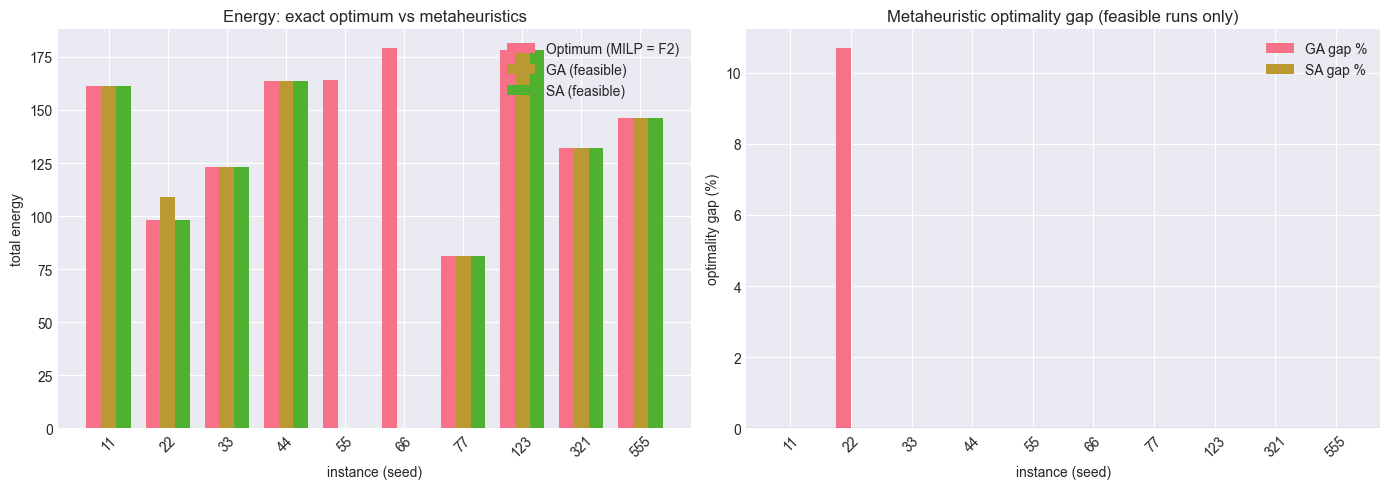

In [24]:
# Comparative plots: energy (exact vs heuristics) and optimality gap
import matplotlib.pyplot as plt
df = results_df.copy()
x = np.arange(len(df)); w = 0.25; labels = [str(s) for s in df['seed']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(x - w, df['optimum'], w, label='Optimum (MILP = F2)')
ax1.bar(x,     df['GA'],      w, label='GA (feasible)')
ax1.bar(x + w, df['SA'],      w, label='SA (feasible)')
ax1.set_xticks(x); ax1.set_xticklabels(labels, rotation=45)
ax1.set_xlabel('instance (seed)'); ax1.set_ylabel('total energy')
ax1.set_title('Energy: exact optimum vs metaheuristics'); ax1.legend()

ax2.bar(x - w/2, df['GA_gap%'], w, label='GA gap %')
ax2.bar(x + w/2, df['SA_gap%'], w, label='SA gap %')
ax2.axhline(0, color='k', lw=0.8); ax2.set_xticks(x); ax2.set_xticklabels(labels, rotation=45)
ax2.set_xlabel('instance (seed)'); ax2.set_ylabel('optimality gap (%)')
ax2.set_title('Metaheuristic optimality gap (feasible runs only)'); ax2.legend()
plt.tight_layout(); plt.show()


### Key insights

**1. The two formulations agree on the optimum.** The arc-based MILP (F1) and the set-partitioning
model (F2) return identical optimal energies on every instance — strong evidence that they model
the same problem at different abstraction levels (arcs vs. whole routes).

**2. Metaheuristics are reliable but must be feasibility-gated.** GA and SA results are counted
only when the returned solution is fully feasible (serve-all + battery + payload + no-fly). There are **no negative optimality gaps**. On feasible runs, **SA matches the
proven optimum more consistently than GA**, which sometimes settles for a costlier route split.

**3. Exact vs. heuristic trade-off.** The exact methods guarantee optimality but cost more time as
instances grow; the metaheuristics return solutions in a fraction of the time, at the price of an
occasional optimality gap.

**4. The custom B&B is exact on small instances.** It explores hundreds of nodes and
matches CBC and F2. On the tightest instances its loose big-M relaxation slows convergence, where
CBC's cuts/presolve and the compact set-partitioning model stay efficient — itself a useful
comparative observation.



# Problem-Specific Components

The operators that will be implemented:
- Energy-Aware Neighborhood: only generate neighbors that respect the remaining battery
- Route Merging: we combine the compatible routes to reduce drone count 
- Customer Clustering: we re-cluster customers geographically
- No-Fly Zone Handling: Path planning with A* or Dijkstra around obstacles

In [25]:
import math
import heapq
import copy
import numpy as np
import random
from typing import Dict, List, Tuple

# ============================================================
# Problem-specific operators (simple, reusable helpers)
# ============================================================

# 1) Customer Clustering (encoding / initialization)

def clustered_customer_order(instance: Dict) -> List[int]:
    """Simple geographic clustering via angular sweep around the depot.

    Produces a permutation of customers 1..n that tends to keep nearby points adjacent.
    """
    depot = np.array(instance["depot"], dtype=float)
    customers = instance["customers"]

    angles = []
    for i, (x, y) in enumerate(customers, start=1):
        v = np.array([x, y], dtype=float) - depot
        angles.append((math.atan2(v[1], v[0]), i))

    angles.sort(key=lambda t: t[0])
    return [i for _, i in angles]


def clustered_initial_routes(instance: Dict, config) -> Dict:
    """Build an initial solution using clustered order + GA's split builder."""
    ga_tmp = GeneticAlgorithm(instance, config, population_size=2, generations=1)
    order = clustered_customer_order(instance)
    return ga_tmp._customers_to_routes(order)


# 2) Route Merging (post-processing improvement)

def split_trips(route: List[int]) -> List[List[int]]:
    """Split a route into trips (lists of customers), using 0 as separator."""
    trips = []
    current = []
    for node in route:
        if node == 0:
            if current:
                trips.append(current)
                current = []
        else:
            current.append(node)
    if current:
        trips.append(current)
    return trips


def build_route_from_trips(trips: List[List[int]]) -> List[int]:
    """Rebuild route list with depot markers from trips."""
    route = [0]
    for t in trips:
        route.extend(t)
        route.append(0)
    if route[-1] != 0:
        route.append(0)
    return route


def trip_energy_and_payload(trip: List[int], instance: Dict, config) -> Tuple[float, float]:
    e = instance["energy_matrix"]
    d = [0] + instance["demands"]

    if not trip:
        return 0.0, 0.0

    energy = e[0][trip[0]]
    for a, b in zip(trip, trip[1:]):
        energy += e[a][b]
    energy += e[trip[-1]][0]

    payload = sum(d[c] for c in trip)
    return float(energy), float(payload)


def try_merge_two_trips(trip_a: List[int], trip_b: List[int], instance: Dict, config) -> List[int] | None:
    """Try to merge trips by concatenation (a then b). Return merged trip or None."""
    merged = trip_a + trip_b
    energy, payload = trip_energy_and_payload(merged, instance, config)
    if energy <= config.battery_capacity + 1e-6 and payload <= config.payload_capacity + 1e-6:
        return merged
    return None


def merge_routes(solution_routes: Dict, instance: Dict, config) -> Dict:
    """Attempt simple trip merges within each drone route to reduce depot returns."""
    improved = copy.deepcopy(solution_routes)

    for k, route in improved.items():
        trips = split_trips(route)
        if len(trips) < 2:
            continue

        changed = True
        while changed:
            changed = False
            # Try to merge adjacent trips greedily
            new_trips = []
            i = 0
            while i < len(trips):
                if i < len(trips) - 1:
                    merged = try_merge_two_trips(trips[i], trips[i + 1], instance, config)
                    if merged is not None:
                        new_trips.append(merged)
                        i += 2
                        changed = True
                        continue
                new_trips.append(trips[i])
                i += 1
            trips = new_trips

        improved[k] = build_route_from_trips(trips)

    return improved


def sanitize_heuristic_energy(instance: Dict, config) -> Dict:
    """Make energy costs safe for heuristics: blocked arcs get a big penalty; zero/invalid arcs use distance."""
    inst = copy.deepcopy(instance)
    e = np.array(inst["energy_matrix"], dtype=float)
    dist = np.array(inst["distance_matrix"], dtype=float)
    n = e.shape[0]
    fa = inst.get("feasible_arc")
    avg_payload = float(np.mean(inst["demands"])) * 0.6
    big = 50.0 * float(config.battery_capacity)

    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            if fa is not None and not fa[i][j]:
                e[i, j] = big
            elif e[i, j] <= 0:
                e[i, j] = float(config.energy_consumption(float(dist[i, j]), avg_payload))

    inst["energy_matrix"] = e
    return inst


# 3) Energy-aware neighborhood (for SA / local search)

def energy_aware_neighbor_pick(get_neighbor, instance, config, current_solution: Dict, max_tries: int = 30) -> Dict:
    """Try get_neighbor(solution) until a feasible route set is found (non-recursive)."""
    for _ in range(max_tries):
        nb = get_neighbor(current_solution)
        if route_feasible_serve_all(nb, instance, config):
            return nb
    return get_neighbor(current_solution)


# 4) No-fly zone handling via shortest-path energy substitution

def add_no_fly_shortest_paths(instance: Dict, config) -> Dict:
    """All-pairs shortest-path energy on the *feasible* arc graph; distance-based weights/fallbacks (no 1e9)."""
    inst = copy.deepcopy(instance)
    e0 = np.array(inst["energy_matrix"], dtype=float)
    dist = np.array(inst["distance_matrix"], dtype=float)
    n = e0.shape[0]

    feasible = inst.get("feasible_arc")
    if feasible is None:
        feasible = np.ones((n, n), dtype=bool)
        for i in range(n):
            for j in range(n):
                feasible[i, j] = i != j

    avg_payload = float(np.mean(inst["demands"])) * 0.6

    def edge_weight(u: int, v: int):
        if u == v or not feasible[u, v]:
            return None
        w = float(e0[u, v])
        if w <= 0:
            w = float(config.energy_consumption(float(dist[u, v]), avg_payload))
        return w

    sp = np.full((n, n), np.inf, dtype=float)

    for src in range(n):
        dvec = [float("inf")] * n
        dvec[src] = 0.0
        pq = [(0.0, src)]
        while pq:
            du, u = heapq.heappop(pq)
            if du != dvec[u]:
                continue
            for v in range(n):
                w = edge_weight(u, v)
                if w is None:
                    continue
                nd = du + w
                if nd < dvec[v]:
                    dvec[v] = nd
                    heapq.heappush(pq, (nd, v))
        sp[src, :] = dvec

    for i in range(n):
        for j in range(n):
            if i != j and not np.isfinite(sp[i, j]):
                sp[i, j] = float(config.energy_consumption(float(dist[i, j]), avg_payload))

    inst["energy_matrix"] = sp
    return inst


## Comparing GA / SA with vs. without the operators

We test whether the four problem-specific operators actually help. For each instance we run the
GA→SA pipeline twice — once plain, once with operators (clustered initialisation, no-fly
shortest-path energies, energy-aware neighbourhood, and route merging). The operators only *shape
the search*; every final solution is judged on the **true instance** (original energies and no-fly
arcs), and a run is compared only when **both** variants are feasible, so the comparison is like-for-like.


 seed  n  GA_base  GA_ops  GA_base_feas  GA_ops_feas  SA_base  SA_ops  SA_base_feas  SA_ops_feas
  201  6   132.57  132.57          True         True   132.57  132.57          True         True
  202  6      NaN     NaN         False        False      NaN     NaN         False        False
  203  6   140.85  140.85          True         True   140.85  140.85          True         True
  204  6   162.45  151.41          True         True   146.51  146.51          True         True
  205  6      NaN     NaN         False        False      NaN     NaN         False        False
  206  6      NaN     NaN         False        False      NaN     NaN         False        False

GA: both feasible on 3/6; avg energy change (ops - base): -3.68  (negative = operators help)
SA: both feasible on 3/6; avg energy change (ops - base): 0.00


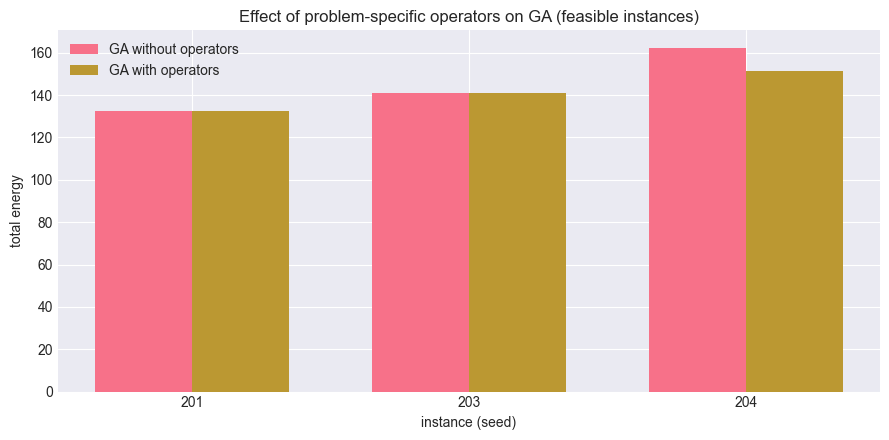

In [26]:
# With vs. without problem-specific operators (feasibility-gated, judged on the TRUE instance)
import copy, random, io, contextlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def run_with_ops(instance, config, *, use_operators, ga_pop=40, ga_gen=60, sa_time=8):
    heur = (add_no_fly_shortest_paths(copy.deepcopy(instance), config)
            if use_operators else copy.deepcopy(instance))
    heur = sanitize_heuristic_energy(heur, config)

    ga = GeneticAlgorithm(heur, config, population_size=ga_pop, generations=ga_gen)
    if use_operators:                                   # operator: clustered initialisation
        def _init():
            pop = [clustered_initial_routes(heur, config)]
            cs = list(range(1, ga.n + 1))
            for _ in range(ga.pop_size - 1):
                random.shuffle(cs); pop.append(ga._customers_to_routes(cs))
            return pop
        ga.initialize_population = _init
    ga_routes = ga.solve()
    if use_operators:                                   # operator: route merging
        ga_routes = merge_routes(ga_routes, heur, config)
    ga_feas = route_feasible_serve_all(ga_routes, instance, config)
    ga_e = evaluate(ga_routes, instance, config)[0] if ga_feas else float('nan')

    sa = SimulatedAnnealing(heur, config, time_limit=sa_time)
    if use_operators:                                   # operator: energy-aware neighbourhood
        _orig = sa.get_neighbor
        sa.get_neighbor = lambda s: energy_aware_neighbor_pick(_orig, instance, config, s, max_tries=12)
    sa_routes = sa.solve(initial_solution=ga_routes)
    if use_operators:
        sa_routes = merge_routes(sa_routes, heur, config)
    sa_feas = route_feasible_serve_all(sa_routes, instance, config)
    sa_e = evaluate(sa_routes, instance, config)[0] if sa_feas else float('nan')
    return ga_e, ga_feas, sa_e, sa_feas


OPS_SEEDS = [201, 202, 203, 204, 205, 206]
ops_cfg = ProblemConfig(); ops_cfg.max_trips_per_drone = 2
rows = []
for seed in OPS_SEEDS:
    np.random.seed(seed); random.seed(seed)
    with contextlib.redirect_stdout(io.StringIO()):
        inst = InstanceGenerator(ops_cfg).generate_instance(12)
        pp = preprocess_customer_selection(inst, ops_cfg, k_max=6)
        gb, gbf, sb, sbf = run_with_ops(pp, ops_cfg, use_operators=False)
        go, gof, so, sof = run_with_ops(pp, ops_cfg, use_operators=True)
    rows.append({'seed': seed, 'n': pp['num_customers'],
                 'GA_base': gb, 'GA_ops': go, 'GA_base_feas': gbf, 'GA_ops_feas': gof,
                 'SA_base': sb, 'SA_ops': so, 'SA_base_feas': sbf, 'SA_ops_feas': sof})
ops_df = pd.DataFrame(rows)
print(ops_df.round(2).to_string(index=False))

gap = ops_df[ops_df['GA_base_feas'] & ops_df['GA_ops_feas']]
sap = ops_df[ops_df['SA_base_feas'] & ops_df['SA_ops_feas']]
print(f"\nGA: both feasible on {len(gap)}/{len(ops_df)}; "
      f"avg energy change (ops - base): {(gap['GA_ops']-gap['GA_base']).mean():.2f}  (negative = operators help)")
print(f"SA: both feasible on {len(sap)}/{len(ops_df)}; "
      f"avg energy change (ops - base): {(sap['SA_ops']-sap['SA_base']).mean():.2f}")

# Plot per-instance GA base vs ops (feasible instances)
plot_df = gap.copy()
if not plot_df.empty:
    x = np.arange(len(plot_df)); w = 0.35
    plt.figure(figsize=(9, 4.5))
    plt.bar(x - w/2, plot_df['GA_base'], w, label='GA without operators')
    plt.bar(x + w/2, plot_df['GA_ops'],  w, label='GA with operators')
    plt.xticks(x, [str(s) for s in plot_df['seed']])
    plt.xlabel('instance (seed)'); plt.ylabel('total energy')
    plt.title('Effect of problem-specific operators on GA (feasible instances)')
    plt.legend(); plt.tight_layout(); plt.show()
